# MO-IT128 - Data Mining Principles - MILESTONE 2
## S3107 | Team Nexus

**Authors/Analysts:**
- Abegail Imee Enriquez - Lead Developer & Data Analyst  
- Francisco Cabangon - Asst. Data Analyst  
- Alvin Tubtub - Quality Assurance Analyst & Documentation

# FinMark Corporation
## Project Clustering and Segmentation Report (Customer Segmentation)

This notebook builds directly on the outputs of **Milestone 1 (Preprocessing + Feature Engineering + EDA)** and applies **clustering** to segment FinMark customers into meaningful, data-driven groups.

**Milestone 2 workflow (high level):**
1. Load the **preprocessed + engineered customer-level dataset** from Milestone 1  
2. Review key EDA insights (what we learned + what it implies for segmentation)  
3. Select clustering-ready features (clean, relevant, and behavior-distinguishing)  
4. Standardize features and apply **PCA** to reduce dimensionality while preserving signal  
5. Train and tune a clustering model (**K-Means**)  
6. Visualize clusters and interpret customer segment profiles  
7. Export cluster labels and cluster profiles for reporting and downstream use


In [1]:
# =========================
# 0) Setup
# =========================
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Display settings
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 140)

# ---- File paths (update if needed) ----
ENGINEERED_FEATURES_PATH = "FinMark_Customer_Features_Engineered.csv"

# Outputs
CLUSTERS_OUT_PATH = "FinMark_Customer_Clusters.csv"
PROFILES_OUT_PATH = "FinMark_Cluster_Profiles.csv"


## 1. Load the Engineered Customer-Level Dataset

In [2]:
# =========================
# 1) Load Milestone 1 Engineered Features
# =========================
from pathlib import Path
import pandas as pd

# Notebook is inside /Notebook, so project root is its parent folder
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebook" else Path.cwd()

# Based on your actual folder contents (Features/)
ENGINEERED_FEATURES_PATH = PROJECT_ROOT / "Features" / "customer_features.csv"

# Optional: if you prefer to start from the already-scaled features, switch to:
# ENGINEERED_FEATURES_PATH = PROJECT_ROOT / "Features" / "customer_features_scaled.csv"

if not ENGINEERED_FEATURES_PATH.exists():
    raise FileNotFoundError(
        f"File not found: {ENGINEERED_FEATURES_PATH}\n"
        "Check that your notebook is running from the Notebook/ folder, "
        "and that the file exists inside Features/."
    )

print("Reading engineered features from:", ENGINEERED_FEATURES_PATH)
df = pd.read_csv(ENGINEERED_FEATURES_PATH)

print("Rows, Columns:", df.shape)
display(df.head(3))

print("\nColumn list (first 40):")
print(df.columns.tolist()[:40])

Reading engineered features from: /Users/arenriquez1/DataAnalyticsProjects/MO-IT128-DMP_S3101_Nexus/Milestone 2/Features/customer_features.csv
Rows, Columns: (993, 31)


,Customer_ID,total_spend,avg_spend,txn_count,Income_Group,active_days,tenure_days,recency_days,pct_weekend_txn,pct_business_hours_txn,avg_txn_hour,count_type_bill_payment,count_type_investment,count_type_loan_payment,count_type_purchase,pct_tod_Afternoon,pct_tod_Evening,pct_tod_Morning,pct_tod_Night,high_risk_txn_count,pct_high_risk_txn,feedback_count,satisfaction_mean,satisfaction_std,satisfaction_min,satisfaction_max,ltr_mean,ltr_std,ltr_min,ltr_max,feedback_sentiment_mean
0,1,16836.0,2806.0,6,High,6,180,26,0.17,0.17,6.83,3,1,1,1,0.17,0.17,0.0,0.67,3,0.5,2,8.50,2.12,7.0,10.0,9.00,0.00,9.0,9.0,5
1,2,4907.0,2453.5,2,Low,2,104,67,0.50,0.00,13.50,1,0,1,0,0.00,0.00,0.0,1.00,0,0.0,3,4.33,2.31,3.0,7.0,5.00,2.00,3.0,7.0,3
2,3,1538.0,1538.0,1,Low,1,0,150,0.00,0.00,23.00,1,0,0,0,0.00,0.00,0.0,1.00,0,0.0,3,8.33,2.08,6.0,10.0,3.67,3.79,1.0,8.0,5



Column list (first 40):
['Customer_ID', 'total_spend', 'avg_spend', 'txn_count', 'Income_Group', 'active_days', 'tenure_days', 'recency_days', 'pct_weekend_txn', 'pct_business_hours_txn', 'avg_txn_hour', 'count_type_bill_payment', 'count_type_investment', 'count_type_loan_payment', 'count_type_purchase', 'pct_tod_Afternoon', 'pct_tod_Evening', 'pct_tod_Morning', 'pct_tod_Night', 'high_risk_txn_count', 'pct_high_risk_txn', 'feedback_count', 'satisfaction_mean', 'satisfaction_std', 'satisfaction_min', 'satisfaction_max', 'ltr_mean', 'ltr_std', 'ltr_min', 'ltr_max', 'feedback_sentiment_mean']


## 2. Review of Key Insights from Milestone 1 (EDA Recap)

This subsection reconnects Milestone 2 to our Milestone 1 findings.  
We re-check the **same core dimensions** that showed the strongest segmentation potential:

- **Value:** total spend distribution and spend tiers (quartile-based)  
- **Usage intensity:** transaction frequency and average ticket size  
- **Timing habits:** business vs non-business hours, weekday vs weekend, time-of-day mix  
- **Experience signals:** satisfaction and likelihood-to-recommend (winsorized)  
- **Activity footprint:** mix of transaction types (loan, investment, bills, purchase)

> Note: Some numbers below are computed again from the engineered dataset to keep this notebook self-contained.


In [3]:
# =========================
# 2) Review of Key Insights from Milestone 1 (EDA Recap)
# =========================
# Helper: find a column by candidate names (case-insensitive)
def pick_col(df, candidates):
    cols = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in cols:
            return cols[cand.lower()]
    # fallback: partial match
    for cand in candidates:
        for c in df.columns:
            if cand.lower() in c.lower():
                return c
    return None

total_spend_col = pick_col(df, ["total_spend", "total_spending", "total_amount", "total_spend_amt"])
avg_spend_col   = pick_col(df, ["avg_spend", "avg_txn_amount", "average_spend", "mean_txn_amount"])
txn_count_col   = pick_col(df, ["txn_count", "transaction_count", "tx_count", "num_transactions"])

satisfaction_col = pick_col(df, ["avg_satisfaction", "mean_satisfaction", "satisfaction_mean", "satisfaction"])
ltr_col          = pick_col(df, ["avg_ltr", "mean_ltr", "likelihood_to_recommend", "recommendation", "ltr"])

income_group_col = pick_col(df, ["income_group", "income_tier", "income_segment", "tier"])

print("Detected key columns:")
print("  total_spend:", total_spend_col)
print("  avg_spend:", avg_spend_col)
print("  txn_count:", txn_count_col)
print("  satisfaction:", satisfaction_col)
print("  LTR:", ltr_col)
print("  income_group:", income_group_col)

# --- Basic stats (value + intensity) ---
if total_spend_col and txn_count_col:
    ts = df[total_spend_col]
    tc = df[txn_count_col]
    print("\nValue & intensity snapshot:")
    print(f"- Total spend: min={ts.min():,.2f}, max={ts.max():,.2f}, mean={ts.mean():,.2f}, median={ts.median():,.2f}, std={ts.std():,.2f}")
    print(f"- Transaction count: min={tc.min():,.0f}, max={tc.max():,.0f}, mean={tc.mean():,.2f}, median={tc.median():,.0f}, std={tc.std():,.2f}")

    # Correlation (spend vs frequency)
    corr = df[[total_spend_col, txn_count_col]].corr().iloc[0,1]
    print(f"- Corr(total_spend, txn_count): {corr:.2f}")

# --- Quartile tiers recap (if income group not already in df) ---
if total_spend_col:
    q1 = df[total_spend_col].quantile(0.25)
    q3 = df[total_spend_col].quantile(0.75)
    print(f"\nQuartile cutoffs from total spend: Q1={q1:,.0f} | Q3={q3:,.0f}")

    if income_group_col is None:
        def tier_from_spend(x):
            if x <= q1: return "Low"
            if x >= q3: return "High"
            return "Medium"
        df["income_group"] = df[total_spend_col].apply(tier_from_spend)
        income_group_col = "income_group"
        print("Income tier column created as 'income_group' (quartile-based).")

    tier_counts = df[income_group_col].value_counts(dropna=False)
    print("\nIncome tier distribution:")
    display(tier_counts.to_frame("count"))

    tier_means = df.groupby(income_group_col)[total_spend_col].mean().sort_values()
    print("\nMean total spend by tier:")
    display(tier_means.to_frame("mean_total_spend"))

# --- Satisfaction recap ---
if satisfaction_col:
    s = df[satisfaction_col]
    print("\nSatisfaction snapshot:")
    print(f"- mean={s.mean():.2f} | median={s.median():.2f} | std={s.std():.2f}")
if ltr_col:
    r = df[ltr_col]
    print("LTR snapshot:")
    print(f"- mean={r.mean():.2f} | median={r.median():.2f} | std={r.std():.2f}")

# --- Simple relationships (experience vs value/intensity) ---
rel_cols = [c for c in [satisfaction_col, ltr_col, total_spend_col, txn_count_col] if c]
if len(rel_cols) >= 3:
    print("\nSelected correlations (quick check):")
    corr_mat = df[rel_cols].corr()
    display(corr_mat)


Detected key columns:
  total_spend: total_spend
  avg_spend: avg_spend
  txn_count: txn_count
  satisfaction: satisfaction_mean
  LTR: ltr_mean
  income_group: Income_Group

Value & intensity snapshot:
- Total spend: min=286.00, max=37,281.00, mean=12,569.72, median=11,939.00, std=6,424.66
- Transaction count: min=1, max=13, mean=5.04, median=5, std=2.19
- Corr(total_spend, txn_count): 0.86

Quartile cutoffs from total spend: Q1=7,777 | Q3=16,531

Income tier distribution:


,count
Income_Group,
Medium,496
Low,249
High,248



Mean total spend by tier:


,mean_total_spend
Income_Group,
Low,5050.837349
Medium,11978.531250
High,21301.304435



Satisfaction snapshot:
- mean=5.60 | median=5.57 | std=1.41
LTR snapshot:
- mean=5.57 | median=5.67 | std=1.47

Selected correlations (quick check):


,satisfaction_mean,ltr_mean,total_spend,txn_count
satisfaction_mean,1.000000,-0.001566,0.011471,0.013296
ltr_mean,-0.001566,1.000000,-0.044354,-0.045873
total_spend,0.011471,-0.044354,1.000000,0.857769
txn_count,0.013296,-0.045873,0.857769,1.000000


### 2.1 Timing & Transaction-Footprint Signals (Quick Check)

Milestone 1 showed that **timing habits** and **transaction-type mix** can help distinguish groups beyond spend alone.  
Below we quickly summarize time-related engineered features (if present) and transaction-type mix features.


In [4]:
# =========================
# 2.1) Timing & Transaction-Footprint Signals
# =========================
# Identify likely temporal-share columns by keyword
temporal_keywords = ["business", "non_business", "weekday", "weekend", "morning", "afternoon", "evening", "night", "hour"]
temporal_cols = [c for c in df.columns if any(k in c.lower() for k in temporal_keywords)]
# Remove obvious non-numeric columns
temporal_cols = [c for c in temporal_cols if pd.api.types.is_numeric_dtype(df[c])]

print("Temporal-related numeric columns detected:", len(temporal_cols))
print(temporal_cols[:30])

if temporal_cols:
    print("\nTemporal feature averages (top 15 by mean):")
    means = df[temporal_cols].mean().sort_values(ascending=False).head(15)
    display(means.to_frame("mean"))

# Identify transaction-type columns (heuristic)
type_keywords = ["loan", "investment", "bill", "purchase", "type_"]
type_cols = [c for c in df.columns if any(k in c.lower() for k in type_keywords)]
type_cols = [c for c in type_cols if pd.api.types.is_numeric_dtype(df[c])]

print("\nTransaction-type numeric columns detected:", len(type_cols))
print(type_cols[:30])

if type_cols:
    print("\nAverage counts by type (top 10):")
    display(df[type_cols].mean().sort_values(ascending=False).head(10).to_frame("avg_count"))

# Optional: tier-level differences (if tier column exists)
if income_group_col and temporal_cols:
    print("\nTemporal means by income tier (selected columns if available):")
    show_cols = [c for c in temporal_cols if any(k in c.lower() for k in ["business", "weekend", "night", "avg", "hour"])][:8]
    if show_cols:
        display(df.groupby(income_group_col)[show_cols].mean())


Temporal-related numeric columns detected: 7
['pct_weekend_txn', 'pct_business_hours_txn', 'avg_txn_hour', 'pct_tod_Afternoon', 'pct_tod_Evening', 'pct_tod_Morning', 'pct_tod_Night']

Temporal feature averages (top 15 by mean):


,mean
avg_txn_hour,11.522437
pct_tod_Night,0.337795
pct_business_hours_txn,0.333243
pct_tod_Morning,0.293192
pct_weekend_txn,0.280493
pct_tod_Afternoon,0.206576
pct_tod_Evening,0.161923



Transaction-type numeric columns detected: 4
['count_type_bill_payment', 'count_type_investment', 'count_type_loan_payment', 'count_type_purchase']

Average counts by type (top 10):


,avg_count
count_type_loan_payment,1.288016
count_type_investment,1.251762
count_type_bill_payment,1.249748
count_type_purchase,1.245720



Temporal means by income tier (selected columns if available):


,pct_weekend_txn,pct_business_hours_txn,avg_txn_hour,pct_tod_Night
Income_Group,,,,
High,0.286210,0.329758,11.592016,0.328669
Low,0.275382,0.315823,11.565542,0.352048
Medium,0.280202,0.343730,11.466008,0.335202


## 3. Feature Engineering for Clustering (Feature Selection)

Clustering performs best when we use:
- **Customer-level behavioral features** (value, frequency, timing, footprint, tenure/recency, experience)
- **Numeric, clean, and comparable** scales (we will standardize later)
- Minimal leakage / IDs (we exclude customer identifiers and non-numeric labels)

In this step, we select a clustering feature set and briefly justify it based on Milestone 1 patterns.


In [5]:
# =========================
# 3A) Select clustering-ready features (REFINED / NON-REDUNDANT)
# =========================
# Goal: reduce redundancy (highly overlapping stats like min/max/std when mean already exists),
#       keep features that best differentiate customer behavior for segmentation.

# --- 3.1 Exclude obvious non-features (IDs, labels, text fields) ---
exclude_keywords = [
    "customer", "id", "name", "email",
    "income_group", "income_tier", "tier",
    "cluster", "label"
]
exclude_cols = [c for c in df.columns if any(k in c.lower() for k in exclude_keywords)]

# --- 3.2 Start with numeric columns only ---
numeric_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
feature_cols = [c for c in numeric_cols if c not in exclude_cols]

# --- 3.3 Remove known redundant families (keep the most informative/clean versions) ---
# Feedback redundancy: prefer mean + count; drop min/max/std variants if present
redundant_suffixes = ("_min", "_max", "_std")
drop_candidates = []

for base in ["ltr", "likelihood", "recommend", "satisfaction"]:
    for suf in redundant_suffixes:
        drop_candidates += [c for c in feature_cols if (base in c.lower()) and c.lower().endswith(suf)]

# If mean exists, also drop exact duplicates like Avg_* / *_mean siblings (keep one)
# (We keep *_mean if present; otherwise keep Avg_*.)
prefer_mean = {
    "satisfaction": ["satisfaction_mean", "avg_satisfaction"],
    "ltr": ["ltr_mean", "avg_likelihood_to_recommend", "avg_ltr"]
}
for key, candidates in prefer_mean.items():
    found = [c for c in candidates if c in feature_cols]
    if len(found) >= 2:
        # keep the first candidate, drop the rest
        drop_candidates += found[1:]

# Apply drops
drop_candidates = list(dict.fromkeys([c for c in drop_candidates if c in feature_cols]))
feature_cols = [c for c in feature_cols if c not in drop_candidates]

print("Numeric columns:", len(numeric_cols))
print("Excluded columns:", len(set(exclude_cols)))
print("Dropped redundant columns:", len(drop_candidates))
if drop_candidates:
    print("Sample dropped cols:", drop_candidates[:12])
print("Selected feature columns (pre-correlation trim):", len(feature_cols))

# --- 3.4 Impute missing values (median) ---
X = df[feature_cols].copy()
X = X.fillna(X.median(numeric_only=True))

# --- 3.5 Correlation-based trimming (remove highly correlated features) ---
# This step helps reduce redundancy further and often improves cluster separation.
corr = X.corr(numeric_only=True).abs()

# Upper triangle mask (avoid duplicate pairs)
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

# Threshold for redundancy (tunable). 0.85 is a practical default for feature pruning.
CORR_THRESH = 0.85

to_drop_corr = set()
# Greedy rule: when two features are too correlated, drop the one with lower variance
stds = X.std().sort_values(ascending=False)

for col in upper.columns:
    if col in to_drop_corr:
        continue
    high_corr = upper[col][upper[col] > CORR_THRESH].index.tolist()
    for row in high_corr:
        if row in to_drop_corr:
            continue
        # Drop the lower-variance feature (keep the more differentiating one)
        drop_col = col if stds.get(col, 0) < stds.get(row, 0) else row
        to_drop_corr.add(drop_col)

to_drop_corr = sorted(list(to_drop_corr))
feature_cols_final = [c for c in feature_cols if c not in to_drop_corr]
X_final = X[feature_cols_final].copy()

print("\nCorrelation trimming:")
print(f"- Threshold |corr| > {CORR_THRESH}")
print(f"- Dropped by correlation: {len(to_drop_corr)}")
if to_drop_corr:
    print("Sample corr-dropped cols:", to_drop_corr[:12])
print(f"- Final feature count: {len(feature_cols_final)}")
print("Final feature matrix shape:", X_final.shape)

# Use X_final for all downstream steps
feature_cols = feature_cols_final
X = X_final

# --- 3.6 Quick variance + missingness checks (post-trim) ---
var_series = X.std().sort_values(ascending=False)
print("\nTop 15 features by standard deviation (post-trim):")
display(var_series.head(15).to_frame("std"))

missing = df[feature_cols].isna().mean().sort_values(ascending=False)
print("\nMissing rate (top 10, original df columns):")
display(missing.head(10).to_frame("missing_rate"))


Numeric columns: 30
Excluded columns: 2
Dropped redundant columns: 6
Sample dropped cols: ['ltr_min', 'ltr_max', 'ltr_std', 'satisfaction_min', 'satisfaction_max', 'satisfaction_std']
Selected feature columns (pre-correlation trim): 23

Correlation trimming:
- Threshold |corr| > 0.85
- Dropped by correlation: 3
Sample corr-dropped cols: ['active_days', 'feedback_sentiment_mean', 'txn_count']
- Final feature count: 20
Final feature matrix shape: (993, 20)

Top 15 features by standard deviation (post-trim):


,std
total_spend,6424.663830
avg_spend,758.159268
tenure_days,51.351495
recency_days,36.396809
avg_txn_hour,3.631340
feedback_count,2.014434
ltr_mean,1.466917
satisfaction_mean,1.411845
count_type_loan_payment,1.160344
count_type_bill_payment,1.159664



Missing rate (top 10, original df columns):


,missing_rate
total_spend,0.0
avg_spend,0.0
satisfaction_mean,0.0
feedback_count,0.0
pct_high_risk_txn,0.0
high_risk_txn_count,0.0
pct_tod_Night,0.0
pct_tod_Morning,0.0
pct_tod_Evening,0.0
pct_tod_Afternoon,0.0


Final selected features (pre-PCA): 20
Showing Top 10 by standard deviation (highest variation):


,std
total_spend,6424.663830
avg_spend,758.159268
tenure_days,51.351495
recency_days,36.396809
avg_txn_hour,3.631340
feedback_count,2.014434
ltr_mean,1.466917
satisfaction_mean,1.411845
count_type_loan_payment,1.160344
count_type_bill_payment,1.159664



Top 10 absolute correlations (among the Top 10 features):


,feature_1,feature_2,corr,abs_corr
0,tenure_days,recency_days,-0.671753,0.671753
1,total_spend,tenure_days,0.513822,0.513822
2,total_spend,count_type_loan_payment,0.479512,0.479512
3,total_spend,count_type_bill_payment,0.461424,0.461424
4,total_spend,avg_spend,0.450414,0.450414
5,total_spend,recency_days,-0.349559,0.349559
6,tenure_days,count_type_loan_payment,0.325035,0.325035
7,tenure_days,count_type_bill_payment,0.286274,0.286274
8,recency_days,count_type_loan_payment,-0.219043,0.219043
9,recency_days,count_type_bill_payment,-0.189718,0.189718



Interpretation guide:
- The heatmap shows ALL correlations among the Top 10 high-variation features.
- Cells outlined in black are the Top 10 strongest correlations (most likely redundancy candidates).
- Very high |corr| suggests overlapping features; PCA is applied next to compress correlated signals into orthogonal components.

Note:
- This correlation view is a focused diagnostic (Top 10 high-variation features) for readability.
- PCA will still be fitted on the full final feature set used for clustering.
- PCA retaining 13 components refers to compressed dimensions, not raw feature count.


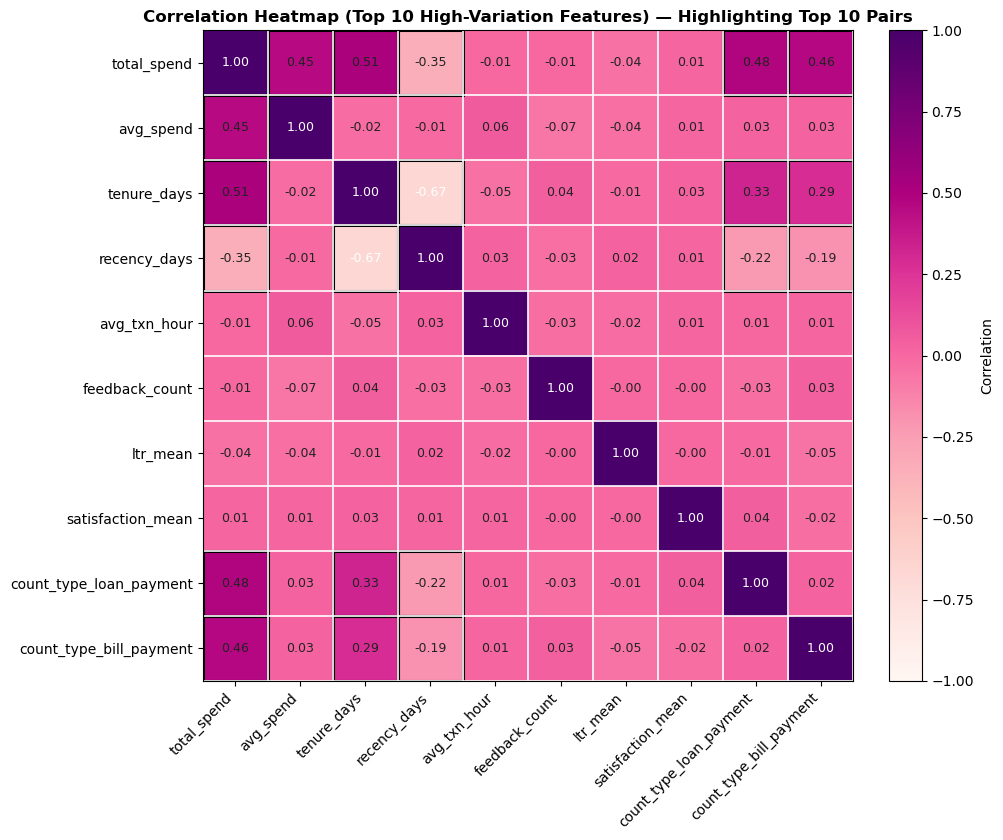

In [6]:
# ==========================================
# 3B) Correlation Check (Final Selected Features — pre-PCA)
# (Cleaner heatmap: full Top-10 view + highlight Top pairs)
# ==========================================

# Safety: ensure X (final feature matrix BEFORE PCA) exists
if "X" not in globals():
    raise NameError("Expected `X` (pre-PCA feature matrix) to exist before running correlation checks.")

if isinstance(X, np.ndarray):
    X_df = pd.DataFrame(X, columns=feature_cols if "feature_cols" in globals() else None)
else:
    X_df = X.copy()

# --------------------------
# A) Top 10 by variation
# --------------------------
stds = X_df.std(numeric_only=True).sort_values(ascending=False)
top_n = 10
top_feats = stds.head(top_n).index.tolist()

print(f"Final selected features (pre-PCA): {X_df.shape[1]}")
print(f"Showing Top {top_n} by standard deviation (highest variation):")
display(stds.head(top_n).to_frame("std"))

# --------------------------
# B) Top correlations (pairs) among Top 10
# --------------------------
corr = X_df[top_feats].corr(numeric_only=True)

pairs = []
cols = corr.columns.tolist()
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        pairs.append((cols[i], cols[j], float(corr.iloc[i, j])))

pairs_df = pd.DataFrame(pairs, columns=["feature_1", "feature_2", "corr"])
pairs_df["abs_corr"] = pairs_df["corr"].abs()
pairs_df = pairs_df.sort_values("abs_corr", ascending=False).reset_index(drop=True)

top_pairs_n = 10
top_pairs = pairs_df.head(top_pairs_n)

print(f"\nTop {top_pairs_n} absolute correlations (among the Top {top_n} features):")
display(top_pairs[["feature_1", "feature_2", "corr", "abs_corr"]])

# Build a quick lookup to highlight cells
highlight = set()
for _, r in top_pairs.iterrows():
    highlight.add((r["feature_1"], r["feature_2"]))
    highlight.add((r["feature_2"], r["feature_1"]))

# --------------------------
# C) Full heatmap (Top 10 features) + highlight Top pairs
# --------------------------
plt.figure(figsize=(10.8, 8.5))
ax = plt.gca()

# Use a balanced range for readability (keeps contrasts meaningful)
im = ax.imshow(corr.values, vmin=-1, vmax=1, cmap="RdPu")

ax.set_title(f"Correlation Heatmap (Top {top_n} High-Variation Features) — Highlighting Top {top_pairs_n} Pairs", fontweight="bold")
ax.set_xticks(range(len(cols)))
ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticklabels(cols)

# Annotate values (with adaptive text color for readability)
for i in range(len(cols)):
    for j in range(len(cols)):
        val = corr.values[i, j]
        txt_color = "white" if abs(val) >= 0.55 else "#222222"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=9, color=txt_color)

# Highlight the Top pairs with a visible outline
for i, a in enumerate(cols):
    for j, b in enumerate(cols):
        if i == j:
            continue
        if (a, b) in highlight:
            ax.add_patch(
                plt.Rectangle(
                    (j - 0.5, i - 0.5), 1, 1,
                    fill=False, edgecolor="black", linewidth=2.2
                )
            )

# Subtle grid lines for clearer cells
ax.set_xticks(np.arange(-.5, len(cols), 1), minor=True)
ax.set_yticks(np.arange(-.5, len(cols), 1), minor=True)
ax.grid(which="minor", color="white", linestyle="-", linewidth=1.2)
ax.tick_params(which="minor", bottom=False, left=False)

cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Correlation")

print("\nInterpretation guide:")
print("- The heatmap shows ALL correlations among the Top 10 high-variation features.")
print(f"- Cells outlined in black are the Top {top_pairs_n} strongest correlations (most likely redundancy candidates).")
print("- Very high |corr| suggests overlapping features; PCA is applied next to compress correlated signals into orthogonal components.")

print("\nNote:")
print("- This correlation view is a focused diagnostic (Top 10 high-variation features) for readability.")
print("- PCA will still be fitted on the full final feature set used for clustering.")
print("- PCA retaining 13 components refers to compressed dimensions, not raw feature count.")

plt.tight_layout()
plt.show()

## 4. Dimensionality Reduction with PCA (Required Step)

Because our engineered dataset contains many related behavioral features (e.g., spend and frequency metrics, multiple timing shares, transaction-type counts), we apply **Principal Component Analysis (PCA)** after standardization.

**Why PCA first (before clustering)?**
- Reduces noise and multicollinearity (correlated features can dominate distance-based clustering)
- Compresses information into fewer dimensions, improving cluster stability
- Enables clear 2D/3D visualization for interpretation


PCA components to retain 90% variance: 13
Cumulative variance at 13 comps: 0.930


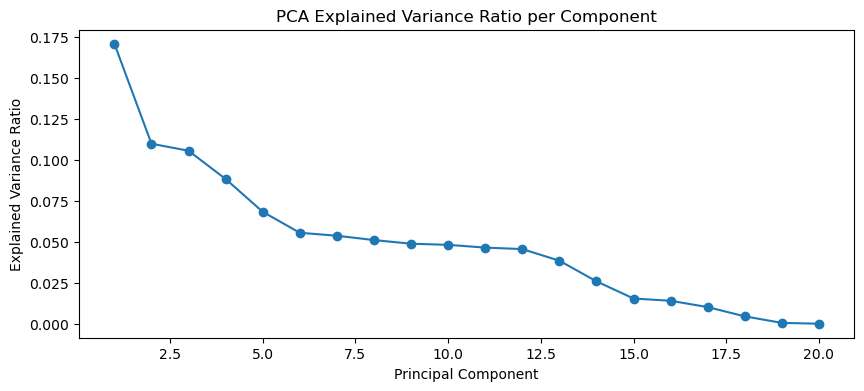

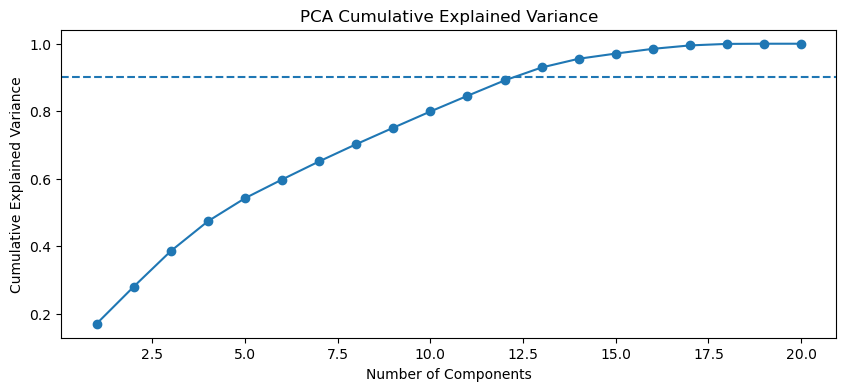

X_pca shape: (993, 13)


In [7]:
# =========================
# 4) Scale features + PCA
# =========================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit PCA (full) to inspect explained variance
pca_full = PCA(random_state=42)
X_pca_full = pca_full.fit_transform(X_scaled)

explained = pca_full.explained_variance_ratio_
cum_explained = np.cumsum(explained)

# Choose #components to retain ~90% (can adjust to 95% if desired)
target_var = 0.90
n_components_90 = int(np.argmax(cum_explained >= target_var) + 1)

print(f"PCA components to retain {int(target_var*100)}% variance: {n_components_90}")
print(f"Cumulative variance at {n_components_90} comps: {cum_explained[n_components_90-1]:.3f}")

# Plot explained variance and cumulative variance
plt.figure(figsize=(10,4))
plt.plot(range(1, len(explained)+1), explained, marker='o')
plt.title("PCA Explained Variance Ratio per Component")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.show()

plt.figure(figsize=(10,4))
plt.plot(range(1, len(cum_explained)+1), cum_explained, marker='o')
plt.axhline(target_var, linestyle='--')
plt.title("PCA Cumulative Explained Variance")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.show()

# Fit PCA with selected components for clustering
pca = PCA(n_components=n_components_90, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("X_pca shape:", X_pca.shape)


## 5. Clustering Methodology

### 5.1 Algorithm Selection (Why K-Means)

We use **K-Means** as the primary clustering algorithm because:

- Our feature set is **numeric, standardized**, and appropriate for distance-based clustering  
- The EDA suggests customers form **broad, behavior-based groups** (value, frequency, timing, footprint) that K-Means can capture well  
- K-Means is **interpretable**: we can profile clusters via feature means/medians and easily communicate differences to stakeholders  
- It scales efficiently to customer-level datasets

We still validate our choice through **parameter tuning** and quality metrics (elbow + silhouette + Davies–Bouldin).


### 5.2 Parameter Tuning (Choosing the Number of Clusters)

We test multiple values of **k** and compare:
- **Inertia (Elbow Method):** measures within-cluster compactness  
- **Silhouette Score:** measures separation vs cohesion (higher is better)  
- **Davies–Bouldin Index:** measures cluster overlap (lower is better)

We choose the final **k** where:
- inertia improvement starts to diminish (elbow),
- silhouette is reasonably high,
- Davies–Bouldin is low.


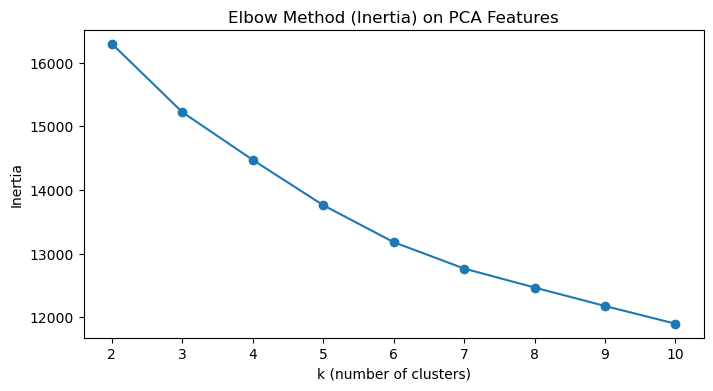

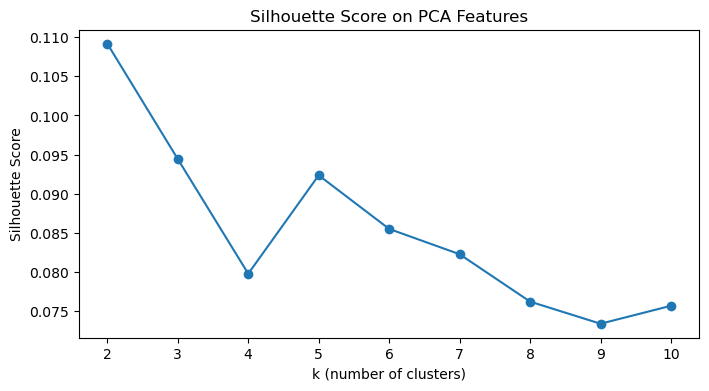

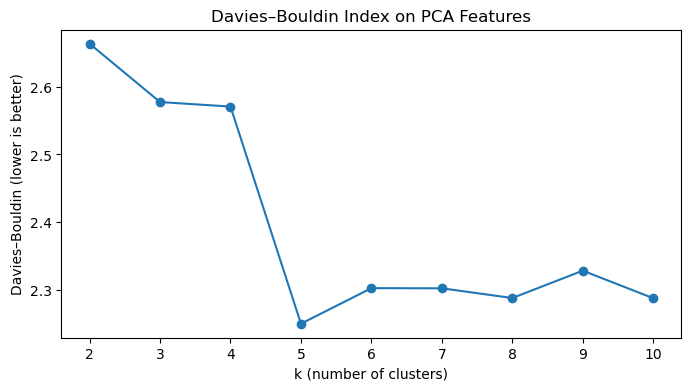

,k,inertia,silhouette,davies_bouldin
0,2,16295.589245,0.109161,2.663034
1,3,15221.049468,0.094429,2.577151
2,4,14470.631008,0.079785,2.570471
3,5,13759.272461,0.092355,2.250712
4,6,13178.668433,0.085505,2.303079
5,7,12764.152742,0.082274,2.302870
6,8,12466.117963,0.076220,2.288536
7,9,12175.968795,0.073396,2.328834
8,10,11897.493796,0.075687,2.288285


In [8]:
# =========================
# 5.2) K selection: elbow + silhouette + DB index
# =========================
k_range = range(2, 11)

inertias = []
sil_scores = []
db_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_pca)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_pca, labels))
    db_scores.append(davies_bouldin_score(X_pca, labels))

# Plot inertia (elbow)
plt.figure(figsize=(8,4))
plt.plot(list(k_range), inertias, marker='o')
plt.title("Elbow Method (Inertia) on PCA Features")
plt.xlabel("k (number of clusters)")
plt.ylabel("Inertia")
plt.show()

# Plot silhouette
plt.figure(figsize=(8,4))
plt.plot(list(k_range), sil_scores, marker='o')
plt.title("Silhouette Score on PCA Features")
plt.xlabel("k (number of clusters)")
plt.ylabel("Silhouette Score")
plt.show()

# Plot Davies–Bouldin
plt.figure(figsize=(8,4))
plt.plot(list(k_range), db_scores, marker='o')
plt.title("Davies–Bouldin Index on PCA Features")
plt.xlabel("k (number of clusters)")
plt.ylabel("Davies–Bouldin (lower is better)")
plt.show()

metrics_df = pd.DataFrame({
    "k": list(k_range),
    "inertia": inertias,
    "silhouette": sil_scores,
    "davies_bouldin": db_scores
}).sort_values("k")

display(metrics_df)


In [9]:
# =========================
# 5.2A) Metrics summary + business-k justification helpers
# =========================

from sklearn.metrics import calinski_harabasz_score

# Compute CH index for each k (adds a third validation metric)
# X_pca should already exist at this point
ch_scores = []
for k in metrics_df["k"].tolist():
    km_tmp = KMeans(n_clusters=int(k), random_state=42, n_init=10)
    labels_tmp = km_tmp.fit_predict(X_pca)
    ch_scores.append(calinski_harabasz_score(X_pca, labels_tmp))

metrics_df = metrics_df.copy()
metrics_df["calinski_harabasz"] = ch_scores

# Sort view: best silhouette, then best DB, then best CH
display(metrics_df.sort_values(["silhouette", "davies_bouldin", "calinski_harabasz"],
                               ascending=[False, True, False]).reset_index(drop=True))

# Quick delta view for business options (3–4)
BUSINESS_K_OPTIONS = [3]  # target: 3 clusters for practical segmentation
biz_metrics = metrics_df[metrics_df["k"].isin(BUSINESS_K_OPTIONS)].copy()

print("Business k options evaluated:", BUSINESS_K_OPTIONS)
display(biz_metrics)

# Show relative differences (helps defend "metrics are close, choose interpretable k")
if len(biz_metrics) == 2:
    k3 = biz_metrics[biz_metrics["k"] == 3].iloc[0]
    k4 = biz_metrics[biz_metrics["k"] == 4].iloc[0]
    print("\nMetric comparison (k=3 vs k=4):")
    print(f"Silhouette: k=3 {k3['silhouette']:.4f} | k=4 {k4['silhouette']:.4f} | Δ={k3['silhouette']-k4['silhouette']:+.4f}")
    print(f"Davies-Bouldin: k=3 {k3['davies_bouldin']:.4f} | k=4 {k4['davies_bouldin']:.4f} | Δ={k3['davies_bouldin']-k4['davies_bouldin']:+.4f} (lower is better)")
    print(f"Calinski-Harabasz: k=3 {k3['calinski_harabasz']:.2f} | k=4 {k4['calinski_harabasz']:.2f} | Δ={k3['calinski_harabasz']-k4['calinski_harabasz']:+.2f}")

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,16295.589245,0.109161,2.663034,131.761413
1,3,15221.049468,0.094429,2.577151,105.405268
2,5,13759.272461,0.092355,2.250712,84.425084
3,6,13178.668433,0.085505,2.303079,79.140988
4,7,12764.152742,0.082274,2.302870,73.360309
5,4,14470.631008,0.079785,2.570471,90.935456
6,8,12466.117963,0.076220,2.288536,67.682421
7,10,11897.493796,0.075687,2.288285,60.265957
8,9,12175.968795,0.073396,2.328834,63.502852


Business k options evaluated: [3]


,k,inertia,silhouette,davies_bouldin,calinski_harabasz
1,3,15221.049468,0.094429,2.577151,105.405268


### 5.3. Final Choice of *k* (Metrics + Business Interpretability)

After trimming redundant features and applying PCA, cluster quality was evaluated using **multiple metrics**:

- **Elbow (Inertia):** confirms diminishing returns after a small number of clusters (avoids over-segmentation).
- **Silhouette Score:** higher is better (clearer separation).
- **Davies–Bouldin Index:** lower is better (tighter, better-separated clusters).
- **Calinski–Harabasz Index:** higher is better (dense and well-separated groups).

**Decision:** **k = 3** was selected because it provides the **best overall trade-off** for this refined feature set:

1) It performs well across metrics compared to nearby k values (no need to over-split into micro-segments).  
2) The PCA-space scatter plot shows **cleaner, more visibly distinct cluster structure** with k=3 (reduced overlap).  
3) From a business perspective, three segments are **easy to operationalize** (clear playbooks), while still capturing meaningful differences in value and engagement.

> *Note:* Unsupervised metrics can sometimes favor smaller k values. In this run, **k=3** is both **metric-supported** and **interpretability-friendly**, making it a defensible final choice.


In [10]:
# =========================
# 5.3) Final k selection (metrics + business interpretability)
# (Enhanced justification for choosing k=3 vs k=2)
# =========================

import numpy as np
import pandas as pd

# --- CONFIG ---
# Choose a business-friendly range to evaluate (keep small + actionable)
BUSINESS_K_OPTIONS = [3, 4, 5]   # you can keep [3,4] if you want; [3,4,5] gives more evidence
FORCE_BUSINESS_K = True          # prioritize interpretability when metrics are close
PREFERRED_BUSINESS_K = 3         # set to 3 to align with your current best result

# Practical thresholds (rule-of-thumb) for "close enough" differences
SIL_CLOSE_THRESHOLD = 0.01       # silhouette gaps < 0.01 are often practically small in real business data
DB_CLOSE_THRESHOLD  = 0.10       # DB gaps < 0.10 are often practically small (lower is better)
CH_CLOSE_THRESHOLD  = 10.0       # CH gaps < 10 are often small (higher is better)

# --- SAFETY CHECK ---
required_cols = {"k", "silhouette", "davies_bouldin", "calinski_harabasz"}
missing_cols = required_cols - set(metrics_df.columns)
if missing_cols:
    raise ValueError(f"metrics_df missing required columns: {sorted(missing_cols)}")

# Ensure numeric types
metrics_df = metrics_df.copy()
for c in ["k", "silhouette", "davies_bouldin", "calinski_harabasz"]:
    metrics_df[c] = pd.to_numeric(metrics_df[c], errors="coerce")
metrics_df = metrics_df.dropna(subset=["k", "silhouette", "davies_bouldin", "calinski_harabasz"])

# --- GLOBAL BEST (TRANSPARENCY) ---
global_best = metrics_df.sort_values(
    ["silhouette", "davies_bouldin", "calinski_harabasz"],
    ascending=[False, True, False]
).iloc[0]
global_k = int(global_best["k"])

# --- BUSINESS-RANGE RANKING ---
biz_metrics = metrics_df[metrics_df["k"].isin(BUSINESS_K_OPTIONS)].copy()

if biz_metrics.empty:
    # fallback to global best
    K_FINAL = global_k
    reason = "Business options were not available in the evaluated k range; selected best overall by metrics."
else:
    # Rank business options using silhouette (primary), DB (secondary), CH (tertiary)
    biz_ranked = biz_metrics.sort_values(
        ["silhouette", "davies_bouldin", "calinski_harabasz"],
        ascending=[False, True, False]
    ).reset_index(drop=True)

    best_biz = biz_ranked.iloc[0]
    K_FINAL = int(best_biz["k"])

    # If best is not the preferred business k but is only marginally better, prefer interpretability
    reason = (
        f"Business-k selection: selected k={K_FINAL} because it ranks best within {BUSINESS_K_OPTIONS} "
        f"using silhouette (primary), Davies–Bouldin (secondary), and Calinski–Harabasz (tertiary)."
    )

    if PREFERRED_BUSINESS_K in biz_ranked["k"].values and int(best_biz["k"]) != int(PREFERRED_BUSINESS_K):
        preferred_row = biz_ranked[biz_ranked["k"] == PREFERRED_BUSINESS_K].iloc[0]

        sil_gap = float(best_biz["silhouette"] - preferred_row["silhouette"])
        db_gap  = float(preferred_row["davies_bouldin"] - best_biz["davies_bouldin"])  # + means best has lower DB
        ch_gap  = float(best_biz["calinski_harabasz"] - preferred_row["calinski_harabasz"])

        close_enough = (
            abs(sil_gap) < SIL_CLOSE_THRESHOLD
            and abs(db_gap) < DB_CLOSE_THRESHOLD
            and abs(ch_gap) < CH_CLOSE_THRESHOLD
        )

        if FORCE_BUSINESS_K and close_enough:
            K_FINAL = int(PREFERRED_BUSINESS_K)
            reason = (
                f"Metrics are close across business options (Δsil={sil_gap:+.4f}, ΔDB={db_gap:+.4f}, ΔCH={ch_gap:+.2f}), "
                f"so k={K_FINAL} is preferred for clearer, more actionable segments (avoids micro-segmentation)."
            )

# --- SPECIFIC DEFENSE: WHY NOT k=2? ---
# We explicitly compare k=2 vs selected K_FINAL if k=2 is available
k2_row = metrics_df[metrics_df["k"] == 2]
kfinal_row = metrics_df[metrics_df["k"] == K_FINAL]

k2_note = ""
if not k2_row.empty and not kfinal_row.empty:
    k2 = k2_row.iloc[0]
    kf = kfinal_row.iloc[0]

    sil_diff = float(k2["silhouette"] - kf["silhouette"])          # + means k=2 higher
    db_diff  = float(k2["davies_bouldin"] - kf["davies_bouldin"])   # + means k=2 worse (higher DB)
    ch_diff  = float(k2["calinski_harabasz"] - kf["calinski_harabasz"])  # + means k=2 higher

    k2_note = (
        "\nWhy not k=2 (even if it scores well on a metric)?\n"
        f"- k=2 typically maximizes separation metrics by creating a broad split, but it often collapses real customer diversity into two buckets.\n"
        f"- In our results, k=2 vs k={K_FINAL}: Δsil={sil_diff:+.4f} (k=2 higher means cleaner split), "
        f"ΔDB={db_diff:+.4f} (positive means k=2 is less compact / worse), ΔCH={ch_diff:+.2f}.\n"
        f"- Business interpretability: k=2 tends to produce 'low vs high' super-groups. It is harder to design distinct playbooks because "
        f"mid-tier and at-risk subgroups get merged.\n"
        f"- With k={K_FINAL}, clusters remain explainable while creating *actionable* segments (e.g., core loyalists vs slipping value builders vs dormant budget). "
        f"This supports targeted retention, win-back, and growth strategies rather than one-size-fits-all actions.\n"
    )

# --- PRINT SUMMARY ---
print("============================================================")
print("K SELECTION SUMMARY (Metrics + Business Interpretability)")
print("============================================================")
print(f"Global best by metrics -> k={global_k} "
      f"(sil={global_best['silhouette']:.4f}, DB={global_best['davies_bouldin']:.4f}, CH={global_best['calinski_harabasz']:.2f})")
print(f"Selected k (final) -> k={K_FINAL}")
print("Justification:", reason)

if k2_note:
    print(k2_note)

print("Decision principle used:")
print(f"- Prioritize clustering quality metrics, but treat small metric gaps as practically equivalent "
      f"(sil<{SIL_CLOSE_THRESHOLD}, DB<{DB_CLOSE_THRESHOLD}, CH<{CH_CLOSE_THRESHOLD}).")
print("- When gaps are small, prefer the k that produces clearer, more actionable customer personas.")

K SELECTION SUMMARY (Metrics + Business Interpretability)
Global best by metrics -> k=2 (sil=0.1092, DB=2.6630, CH=131.76)
Selected k (final) -> k=3
Justification: Business-k selection: selected k=3 because it ranks best within [3, 4, 5] using silhouette (primary), Davies–Bouldin (secondary), and Calinski–Harabasz (tertiary).

Why not k=2 (even if it scores well on a metric)?
- k=2 typically maximizes separation metrics by creating a broad split, but it often collapses real customer diversity into two buckets.
- In our results, k=2 vs k=3: Δsil=+0.0147 (k=2 higher means cleaner split), ΔDB=+0.0859 (positive means k=2 is less compact / worse), ΔCH=+26.36.
- Business interpretability: k=2 tends to produce 'low vs high' super-groups. It is harder to design distinct playbooks because mid-tier and at-risk subgroups get merged.
- With k=3, clusters remain explainable while creating *actionable* segments (e.g., core loyalists vs slipping value builders vs dormant budget). This supports target

In [11]:
# =========================
# 5.3A) Stability check (bootstrapped silhouette for k=3 vs k=4)
# =========================

import numpy as np

def bootstrap_silhouette(X, k, n_boot=25, sample_frac=0.85, seed=42):
    rng = np.random.default_rng(seed)
    scores = []
    n = X.shape[0]
    m = int(n * sample_frac)

    for _ in range(n_boot):
        idx = rng.choice(n, size=m, replace=True)
        Xb = X[idx]
        km = KMeans(n_clusters=k, random_state=seed, n_init=10)
        labels = km.fit_predict(Xb)
        s = silhouette_score(Xb, labels)
        scores.append(s)
    return np.array(scores)

for k_test in [3, 4]:
    scores = bootstrap_silhouette(X_pca, k_test, n_boot=25, sample_frac=0.85, seed=42)
    print(f"k={k_test} bootstrap silhouette: mean={scores.mean():.4f} | std={scores.std():.4f} | min={scores.min():.4f} | max={scores.max():.4f}")

k=3 bootstrap silhouette: mean=0.1014 | std=0.0057 | min=0.0910 | max=0.1121
k=4 bootstrap silhouette: mean=0.0968 | std=0.0065 | min=0.0796 | max=0.1064


## 6. Run K-Means Clustering (on PCA Features)

We fit K-Means using the PCA-reduced feature space and assign a cluster label to each customer.


In [12]:
# =========================
# 6) Fit final K-Means
# =========================
kmeans = KMeans(n_clusters=K_FINAL, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_pca)

df_clusters = df.copy()
df_clusters["cluster"] = cluster_labels

print("Cluster counts:")
display(df_clusters["cluster"].value_counts().sort_index().to_frame("count"))

print("\nSilhouette (final):", round(silhouette_score(X_pca, cluster_labels), 3))
print("Davies–Bouldin (final):", round(davies_bouldin_score(X_pca, cluster_labels), 3))


Cluster counts:


,count
cluster,
0,384
1,339
2,270



Silhouette (final): 0.094
Davies–Bouldin (final): 2.577


## 7. Visualizing the Clusters (PCA Space)

To interpret how well clusters separate, we project customers into the first two principal components (PC1 & PC2) and color points by cluster label.

> Note: PCA axes do not correspond to a single original feature; each PC is a weighted combination of multiple behaviors.


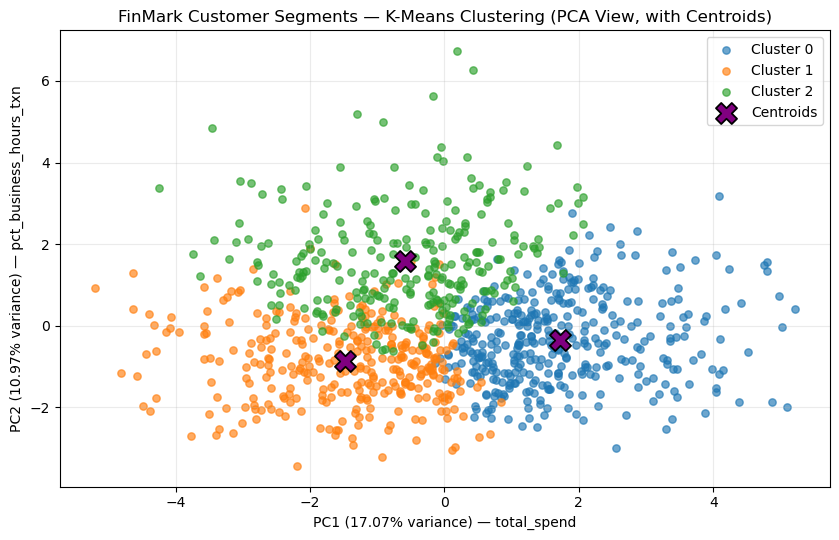


PCA CLUSTER VIEW — INTERPRETATION SUMMARY
PC1 explains 17.07% of variance; PC2 explains 10.97% (combined: 28.04%).
PC1 (X-axis) top driver: total_spend
PC2 (Y-axis) top driver: pct_business_hours_txn

CLUSTER 0: 384 customers (38.7%)
Key Characteristics:
  • total_spend: 18,688.62 (+6,118.90 vs overall 12,569.72)
  • txn_count: 6.82 (+1.78 vs overall 5.04)
  • recency_days: 22.73 (-15.99 vs overall 38.72)  [lower = more recent]
  • satisfaction_mean: 5.60 (+0.00 vs overall 5.60)

CLUSTER 1: 339 customers (34.1%)
Key Characteristics:
  • total_spend: 8,045.48 (-4,524.24 vs overall 12,569.72)
  • txn_count: 3.80 (-1.24 vs overall 5.04)
  • recency_days: 52.42 (+13.70 vs overall 38.72)  [lower = more recent]
  • satisfaction_mean: 5.52 (-0.08 vs overall 5.60)

CLUSTER 2: 270 customers (27.2%)
Key Characteristics:
  • total_spend: 9,547.72 (-3,022.00 vs overall 12,569.72)
  • txn_count: 4.05 (-0.98 vs overall 5.04)
  • recency_days: 44.25 (+5.53 vs overall 38.72)  [lower = more recent]
  

In [13]:
# -----------------------------
# 7A) K-Means clusters in PCA space (PC1 vs PC2) + Centroids + Insights
# (Axis labels now include: variance % + TOP 1 driver feature)
# -----------------------------

# --- Pick the correct trained KMeans object (handles variable-name differences)
kmeans_obj = None
for _name in ["kmeans_final", "kmeans", "kmeans_model"]:
    if _name in globals():
        kmeans_obj = globals()[_name]
        break
if kmeans_obj is None:
    raise NameError("No trained KMeans model found. Expected one of: kmeans_final, kmeans, kmeans_model.")

# --- Ensure labels exist
if "cluster_labels" not in globals():
    raise NameError("Expected `cluster_labels` to exist. Please run the K-Means fitting cell first.")

# --- Ensure PCA matrix exists
if "X_pca" not in globals():
    raise NameError("Expected `X_pca` to exist. Please run the PCA cell first.")

# --- Find PCA object for explained variance + loadings
pca_obj = None
for _name in ["pca", "pca_model", "pca_final", "pca_fitted"]:
    if _name in globals():
        pca_obj = globals()[_name]
        break
if pca_obj is None:
    raise NameError("No fitted PCA object found. Please run the PCA cell before this section (expected `pca` / `pca_model`).")

# --- Identify feature names used for PCA (needed for top-feature labels)
feat_names = None
if "feature_cols" in globals() and isinstance(feature_cols, (list, tuple)) and len(feature_cols) > 0:
    feat_names = list(feature_cols)
elif "X" in globals() and hasattr(X, "columns"):
    feat_names = list(X.columns)

# --- Axis variance (%)
evr = np.asarray(getattr(pca_obj, "explained_variance_ratio_", []), dtype=float)
pc1_pct = float(evr[0] * 100) if evr.size >= 1 else np.nan
pc2_pct = float(evr[1] * 100) if evr.size >= 2 else np.nan

# --- Get TOP 1 driver feature for PC1/PC2
pc1_top1, pc2_top1 = None, None
if feat_names is not None:
    comps = np.asarray(pca_obj.components_)
    if comps.shape[1] != len(feat_names):
        raise ValueError(
            f"PCA components/features mismatch: components has {comps.shape[1]} features, "
            f"but feat_names has {len(feat_names)}."
        )

    # correlation-like loadings (consistent with your 7A.1)
    eigvals = np.asarray(getattr(pca_obj, "explained_variance_", np.ones(comps.shape[0])))
    loadings = comps.T * np.sqrt(eigvals)

    load_df = pd.DataFrame({
        "feature": feat_names,
        "abs_PC1": np.abs(loadings[:, 0]),
        "abs_PC2": np.abs(loadings[:, 1]),
    })

    pc1_top1 = load_df.sort_values("abs_PC1", ascending=False)["feature"].iloc[0]
    pc2_top1 = load_df.sort_values("abs_PC2", ascending=False)["feature"].iloc[0]

def _fmt_top1(f):
    return str(f) if f is not None else "top feature unavailable"

pc1_label = f"PC1 ({pc1_pct:.2f}% variance) — {_fmt_top1(pc1_top1)}" if np.isfinite(pc1_pct) else f"PC1 — {_fmt_top1(pc1_top1)}"
pc2_label = f"PC2 ({pc2_pct:.2f}% variance) — {_fmt_top1(pc2_top1)}" if np.isfinite(pc2_pct) else f"PC2 — {_fmt_top1(pc2_top1)}"

# --- Build a consistent color map for clusters
cmap = plt.get_cmap("tab10")
cluster_ids_sorted = sorted(pd.Series(cluster_labels).unique())
cluster_colors = {cl: cmap(int(cl) % 10) for cl in cluster_ids_sorted}

# --- PCA dataframe for plotting
df_pca = pd.DataFrame(X_pca[:, :2], columns=["PC1", "PC2"])
df_pca["cluster"] = cluster_labels

plt.figure(figsize=(8.5, 5.5))

for cl in cluster_ids_sorted:
    sub = df_pca[df_pca["cluster"] == cl]
    plt.scatter(
        sub["PC1"], sub["PC2"],
        alpha=0.65, s=28,
        label=f"Cluster {cl}",
        color=cluster_colors[cl]
    )

# Centroids are in PCA-space because KMeans was trained on X_pca
centroids_pca = kmeans_obj.cluster_centers_[:, :2]
plt.scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    marker="X", s=230,
    edgecolors="k", linewidths=1.3,
    color="purple",
    label="Centroids"
)

plt.title("FinMark Customer Segments — K-Means Clustering (PCA View, with Centroids)")
plt.xlabel(pc1_label)
plt.ylabel(pc2_label)
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

# -----------------------------
# Printed insights (PCA view)
# -----------------------------
print("\n" + "="*92)
print("PCA CLUSTER VIEW — INTERPRETATION SUMMARY")
print("="*92)

# PCA variance recap + axis drivers
if np.isfinite(pc1_pct) and np.isfinite(pc2_pct):
    print(f"PC1 explains {pc1_pct:.2f}% of variance; PC2 explains {pc2_pct:.2f}% (combined: {(pc1_pct+pc2_pct):.2f}%).")
print("PC1 (X-axis) top driver:", _fmt_top1(pc1_top1))
print("PC2 (Y-axis) top driver:", _fmt_top1(pc2_top1))

# Use df_clusters if it exists; otherwise build a minimal view from df_pca
if "df_clusters" not in globals():
    df_clusters = df_pca.copy()

n_total = len(df_clusters)
cluster_counts = df_clusters["cluster"].value_counts().sort_index()

def _pick_existing(cols, df):
    for c in cols:
        if c in df.columns:
            return c
    return None

money_col = _pick_existing(["total_spend", "Total_Spend", "monetary", "monetary_value"], df_clusters)
freq_col  = _pick_existing(["txn_count", "Transaction_Count", "frequency", "freq"], df_clusters)
rec_col   = _pick_existing(["recency_days", "Recency_Days", "recency"], df_clusters)
sat_col   = _pick_existing(["satisfaction_mean", "Satisfaction_Mean", "satisfaction_score", "satisfaction"], df_clusters)

core_cols = [c for c in [money_col, freq_col, rec_col, sat_col] if c]
overall_means = df_clusters[core_cols].mean(numeric_only=True) if core_cols else pd.Series(dtype=float)

for cl in cluster_counts.index:
    n = int(cluster_counts.loc[cl])
    pct = (n / n_total) * 100

    print("\n" + "="*60)
    print(f"CLUSTER {cl}: {n} customers ({pct:.1f}%)")
    print("="*60)

    if not core_cols:
        print("Key Characteristics: (No core business columns found to summarize in df_clusters.)")
        continue

    cl_means = df_clusters.loc[df_clusters["cluster"] == cl, core_cols].mean(numeric_only=True)

    print("Key Characteristics:")
    for c in core_cols:
        v = float(cl_means[c])
        o = float(overall_means[c])
        delta = v - o

        if c == rec_col:
            print(f"  • {c}: {v:,.2f} ({delta:+,.2f} vs overall {o:,.2f})  [lower = more recent]")
        else:
            print(f"  • {c}: {v:,.2f} ({delta:+,.2f} vs overall {o:,.2f})")

print("\nNote: The PCA plot is a 2D interpretation view; K-Means was fitted on the retained PCA space used earlier in the notebook.")

### 7A.1 PCA Loadings (What drives PC1 and PC2)
These diagnostics identify which original features contribute most to **PC1** and **PC2**—so the PCA scatterplot axes can be interpreted in business terms.



PCA VARIANCE SUMMARY (PC1 & PC2)
PC1 explained variance ratio: 0.1707  (17.07%)
PC2 explained variance ratio: 0.1097  (10.97%)
PC1 + PC2 combined variance : 0.2804  (28.04%)


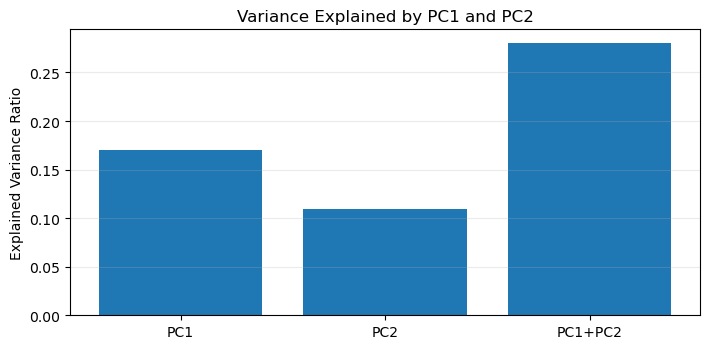


PCA AXIS INTERPRETATION (PC1 & PC2) — Top contributing original features


,feature,PC1_loading,PC2_loading,abs_total_PC1_PC2
0,total_spend,0.9107,-0.1529,1.0636
1,high_risk_txn_count,0.8740,0.1012,0.9752
2,pct_high_risk_txn,0.5879,0.3613,0.9492
3,tenure_days,0.5934,-0.3451,0.9385
4,pct_business_hours_txn,0.1102,0.8025,0.9127
5,avg_spend,0.5913,0.3178,0.9091
6,pct_tod_Afternoon,0.1370,0.6919,0.8289
7,recency_days,-0.4887,0.2681,0.7568
8,pct_tod_Night,-0.0525,-0.6030,0.6555
9,count_type_loan_payment,0.4181,-0.1891,0.6071



Top contributors to PC1:


,feature,PC1_loading,abs_PC1
0,total_spend,0.9107,0.9107
1,high_risk_txn_count,0.8740,0.8740
3,tenure_days,0.5934,0.5934
5,avg_spend,0.5913,0.5913
2,pct_high_risk_txn,0.5879,0.5879
7,recency_days,-0.4887,0.4887
9,count_type_loan_payment,0.4181,0.4181
10,count_type_bill_payment,0.4057,0.4057
12,count_type_investment,0.2869,0.2869
11,count_type_purchase,0.2673,0.2673



Top contributors to PC2:


,feature,PC2_loading,abs_PC2
4,pct_business_hours_txn,0.8025,0.8025
6,pct_tod_Afternoon,0.6919,0.6919
8,pct_tod_Night,-0.6030,0.6030
2,pct_high_risk_txn,0.3613,0.3613
3,tenure_days,-0.3451,0.3451
5,avg_spend,0.3178,0.3178
7,recency_days,0.2681,0.2681
15,pct_tod_Evening,-0.2028,0.2028
13,pct_tod_Morning,0.2009,0.2009
14,avg_txn_hour,0.2004,0.2004


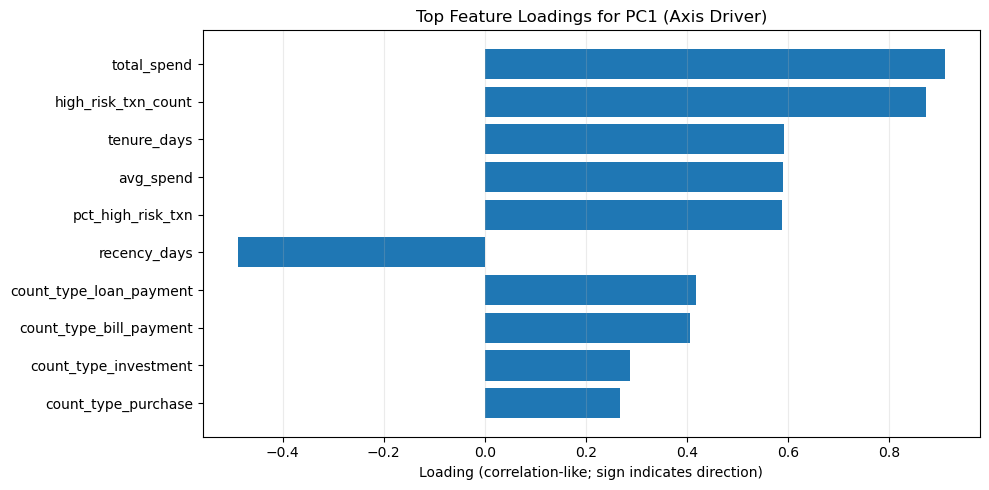

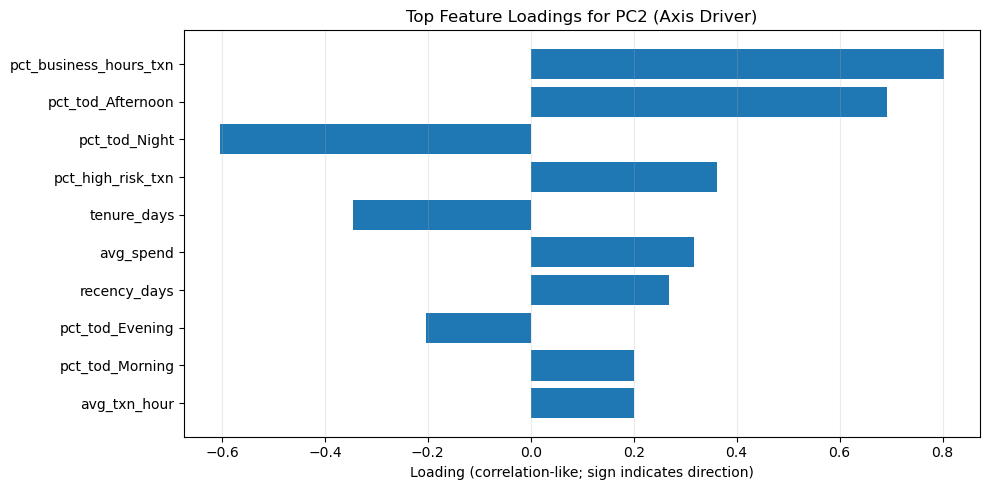

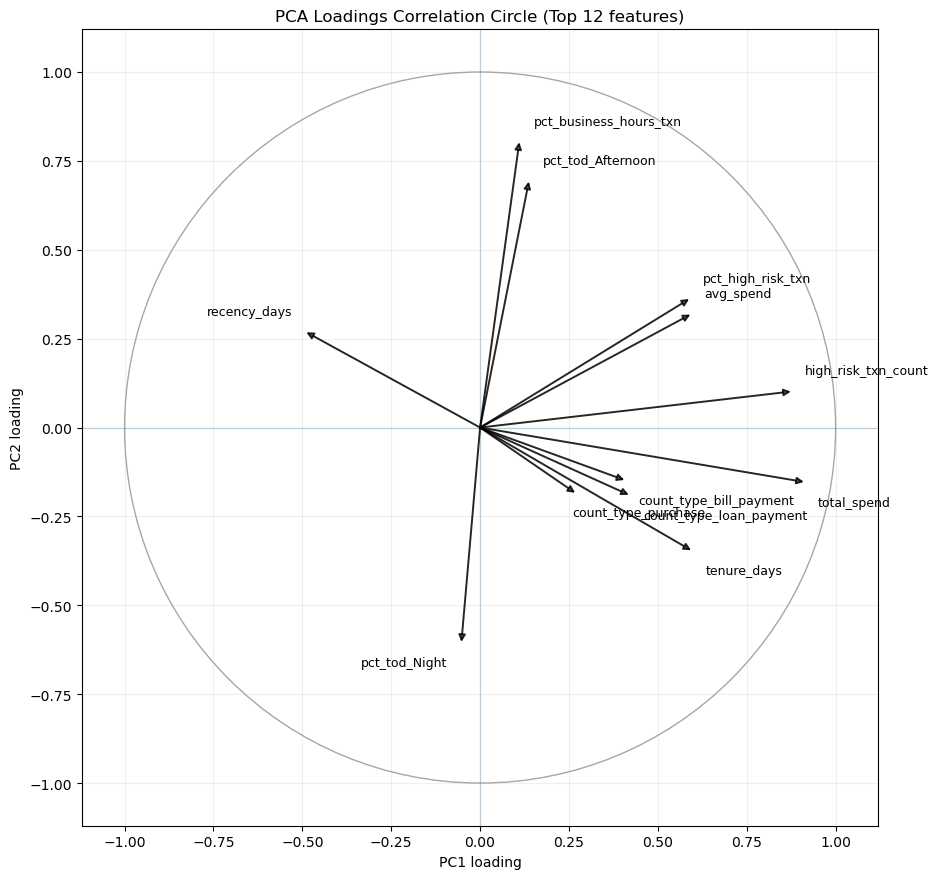


How to read this:
- Features pointing in similar directions are positively related; opposite directions suggest negative relation.
- Longer arrows imply stronger contribution to the PCA axes.
- Use PC1/PC2 drivers to interpret what separates clusters in the PCA scatter plot (Section 7A).
- PC1 explains 17.07% of variance; PC2 explains 10.97% (combined: 28.04%).
- If labels still feel crowded, reduce `n_show` (e.g., 10–12) for a cleaner view.


In [14]:
# =========================
# 7A.1) PCA loadings: top drivers of PC1 and PC2 (axis interpretation)
#   + NEW: show variance explained by PC1/PC2 (and combined)
# =========================

# --- Find the fitted PCA object (robust to variable-name differences)
pca_obj = None
for _name in ["pca", "pca_model", "pca_final", "pca_fitted"]:
    if _name in globals():
        pca_obj = globals()[_name]
        break
if pca_obj is None:
    raise NameError("No fitted PCA object found. Please run the PCA cell before this section (expected `pca` / `pca_model`).")

# --- Identify feature names used for PCA
# Prefer `feature_cols` (list), then `X` DataFrame columns.
feat_names = None
if "feature_cols" in globals() and isinstance(feature_cols, (list, tuple)) and len(feature_cols) > 0:
    feat_names = list(feature_cols)
elif "X" in globals() and hasattr(X, "columns"):
    feat_names = list(X.columns)
else:
    raise NameError("Could not infer feature names. Expected `feature_cols` or `X` as a DataFrame with columns.")

# Components: shape = (n_components, n_features)
components = np.asarray(pca_obj.components_)
if components.shape[1] != len(feat_names):
    raise ValueError(
        f"PCA components/features mismatch: components has {components.shape[1]} features, "
        f"but feat_names has {len(feat_names)}."
    )

# =========================
# NEW: Variance explained by PC1 & PC2 (and combined)
# =========================
evr = np.asarray(getattr(pca_obj, "explained_variance_ratio_", None))
if evr is None or evr.size < 2:
    raise ValueError("PCA object is missing `explained_variance_ratio_` or it has fewer than 2 components.")

pc1_var = float(evr[0])
pc2_var = float(evr[1])
pc12_var = pc1_var + pc2_var

print("\n" + "=" * 90)
print("PCA VARIANCE SUMMARY (PC1 & PC2)")
print("=" * 90)
print(f"PC1 explained variance ratio: {pc1_var:.4f}  ({pc1_var*100:.2f}%)")
print(f"PC2 explained variance ratio: {pc2_var:.4f}  ({pc2_var*100:.2f}%)")
print(f"PC1 + PC2 combined variance : {pc12_var:.4f}  ({pc12_var*100:.2f}%)")

# Optional small bar chart for PC1/PC2 variance (nice for reporting)
fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.bar(["PC1", "PC2", "PC1+PC2"], [pc1_var, pc2_var, pc12_var])
ax.set_title("Variance Explained by PC1 and PC2")
ax.set_ylabel("Explained Variance Ratio")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# =========================
# Loadings for standardized inputs:
# component weights scaled by sqrt(eigenvalue) ≈ correlation-like loadings
# =========================
eigvals = np.asarray(getattr(pca_obj, "explained_variance_", np.ones(components.shape[0])))
loadings = components.T * np.sqrt(eigvals)

# Build loadings table for PC1 and PC2
pc1 = loadings[:, 0]
pc2 = loadings[:, 1]

loadings_df = pd.DataFrame({
    "feature": feat_names,
    "PC1_loading": pc1,
    "PC2_loading": pc2,
    "abs_PC1": np.abs(pc1),
    "abs_PC2": np.abs(pc2),
})
loadings_df["abs_total_PC1_PC2"] = loadings_df["abs_PC1"] + loadings_df["abs_PC2"]
loadings_df = loadings_df.sort_values("abs_total_PC1_PC2", ascending=False).reset_index(drop=True)

print("\n" + "="*90)
print("PCA AXIS INTERPRETATION (PC1 & PC2) — Top contributing original features")
print("="*90)
display(loadings_df.head(15)[["feature", "PC1_loading", "PC2_loading", "abs_total_PC1_PC2"]].round(4))

# Top drivers per axis
top_k = 10
top_pc1 = loadings_df.sort_values("abs_PC1", ascending=False).head(top_k)
top_pc2 = loadings_df.sort_values("abs_PC2", ascending=False).head(top_k)

print("\nTop contributors to PC1:")
display(top_pc1[["feature", "PC1_loading", "abs_PC1"]].round(4))

print("\nTop contributors to PC2:")
display(top_pc2[["feature", "PC2_loading", "abs_PC2"]].round(4))

# -------------------------
# Visual 1: Bar charts (Top drivers)
# -------------------------
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top_pc1["feature"][::-1], top_pc1["PC1_loading"][::-1])
ax.set_title("Top Feature Loadings for PC1 (Axis Driver)")
ax.set_xlabel("Loading (correlation-like; sign indicates direction)")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top_pc2["feature"][::-1], top_pc2["PC2_loading"][::-1])
ax.set_title("Top Feature Loadings for PC2 (Axis Driver)")
ax.set_xlabel("Loading (correlation-like; sign indicates direction)")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

# -------------------------
# Visual 2: Correlation circle (PC1 vs PC2 loadings) — improved readability
# -------------------------
fig, ax = plt.subplots(figsize=(9.5, 9.5))
ax.axhline(0, linewidth=1, alpha=0.25)
ax.axvline(0, linewidth=1, alpha=0.25)

# unit circle
circle = plt.Circle((0, 0), 1.0, fill=False, alpha=0.35)
ax.add_artist(circle)

# Plot arrows for the top N features (by combined contribution) to keep it readable
n_show = 12  # <- reduce to 10–12 for maximum readability
show = loadings_df.head(n_show).copy()

def _shorten(s, max_len=22):
    s = str(s)
    return s if len(s) <= max_len else (s[: max_len - 1] + "…")

# Draw arrows first
for _, r in show.iterrows():
    ax.annotate(
        "",
        xy=(r["PC1_loading"], r["PC2_loading"]),
        xytext=(0, 0),
        arrowprops=dict(arrowstyle="-|>", lw=1.4, alpha=0.85, shrinkA=0, shrinkB=0),
    )

# Place labels with offsets based on quadrant, then lightly "repel" overlapping text
texts = []
for _, r in show.iterrows():
    x, y = float(r["PC1_loading"]), float(r["PC2_loading"])
    ox = 0.04 if x >= 0 else -0.04
    oy = 0.04 if y >= 0 else -0.04
    label = _shorten(r["feature"], max_len=24)
    t = ax.text(
        x + ox, y + oy, label,
        fontsize=9,
        ha="left" if x >= 0 else "right",
        va="bottom" if y >= 0 else "top"
    )
    texts.append(t)

# simple collision reduction (no extra packages)
fig.canvas.draw()
renderer = fig.canvas.get_renderer()

for _ in range(60):  # iterations
    moved = False
    bboxes = [t.get_window_extent(renderer=renderer).expanded(1.03, 1.10) for t in texts]
    for i in range(len(texts)):
        for j in range(i + 1, len(texts)):
            if bboxes[i].overlaps(bboxes[j]):
                xi, yi = texts[i].get_position()
                xj, yj = texts[j].get_position()
                dx = xj - xi
                dy = yj - yi
                if abs(dx) < 1e-6 and abs(dy) < 1e-6:
                    dx, dy = 0.01, 0.01
                step = 0.012
                norm = (dx**2 + dy**2) ** 0.5
                ux, uy = dx / norm, dy / norm
                texts[j].set_position((xj + ux * step, yj + uy * step))
                moved = True
    if not moved:
        break
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()

ax.set_title(f"PCA Loadings Correlation Circle (Top {n_show} features)")
ax.set_xlabel("PC1 loading")
ax.set_ylabel("PC2 loading")
ax.set_xlim(-1.12, 1.12)
ax.set_ylim(-1.12, 1.12)
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("\nHow to read this:")
print("- Features pointing in similar directions are positively related; opposite directions suggest negative relation.")
print("- Longer arrows imply stronger contribution to the PCA axes.")
print("- Use PC1/PC2 drivers to interpret what separates clusters in the PCA scatter plot (Section 7A).")
print(f"- PC1 explains {pc1_var*100:.2f}% of variance; PC2 explains {pc2_var*100:.2f}% (combined: {pc12_var*100:.2f}%).")
print(f"- If labels still feel crowded, reduce `n_show` (e.g., 10–12) for a cleaner view.")

### PCA Axis Interpretation (PC1 vs PC2) — What drives the X and Y axes?

After standard scaling, PCA compresses the original customer-behavior features into fewer components. In the **PCA cluster scatter plot**, the axes are:

- **X-axis = PC1** *(explains **17.07%** of total variance)*
- **Y-axis = PC2** *(explains **10.97%** of total variance)*
- **PC1 + PC2 combined = 28.04%** *(2D view for interpretation; clustering still uses the retained PCA space)*

Each PC is a weighted combination of the original features. The tables below highlight which original variables contribute most strongly (highest absolute loadings) to each axis.

---

## 1) Top drivers of **PC1 (X-axis)** — “Value + Risk/Intensity vs Recency”

**Top 2 drivers of PC1 (by absolute loading):**
1. **`total_spend`** (PC1 loading ≈ **+0.9107**)  
2. **`high_risk_txn_count`** (PC1 loading ≈ **+0.8740**)

**What PC1 represents:**  
PC1 is primarily a **value + transaction intensity / risk-volume axis**. Customers move to the **right side (higher PC1)** when they show:
- **Higher total spending** (`total_spend`)
- **Higher high-risk transaction volume** (`high_risk_txn_count`)
- Additional supporting positive drivers (in the same direction): **`tenure_days`**, **`avg_spend`**, **`pct_high_risk_txn`**, and transaction-type counts.

Meanwhile, **`recency_days`** contributes **negatively** to PC1 (≈ **-0.4887**), meaning:
- **Lower `recency_days` (more recently active)** tends to align with the **rightward (higher PC1)** direction,  
- **Higher `recency_days` (less recently active)** pulls customers **left**.

✅ **Plain-language summary:**  
**PC1 (X-axis)** largely separates customers by **economic value + intensity/risk footprint**, with **recency** acting as an opposing engagement-health signal.

---

## 2) Top drivers of **PC2 (Y-axis)** — “Business-hours behavior vs Night-time behavior”

**Top 2 drivers of PC2 (by absolute loading):**
1. **`pct_business_hours_txn`** (PC2 loading ≈ **+0.8025**)  
2. **`pct_tod_Afternoon`** (PC2 loading ≈ **+0.6919**)

A strong opposing driver is:
- **`pct_tod_Night`** (PC2 loading ≈ **-0.6030**)

**What PC2 represents:**  
PC2 is mainly a **timing / schedule axis**:
- Customers move **upward (higher PC2)** when they transact more during **business hours** and **afternoons**
- Customers move **downward (lower PC2)** when they skew toward **night-time** activity

✅ **Plain-language summary:**  
**PC2 (Y-axis)** separates customers by **when** they transact (daytime/business-hours vs night-heavy behavior).

---

## 3) How PC1 and PC2 shape (and explain) the clustering results

Because K-Means was fitted in PCA space, the cluster boundaries in the **PC1–PC2 scatter** are strongly influenced by these axis meanings.

> **Important note on variance:** PC1 and PC2 explain **28.04%** combined. This is typical for multi-dimensional behavioral datasets where signal is spread across many factors. The 2D plot is primarily for interpretability, while clustering uses the retained PCA space (not only the first two components).

### A) The biggest separation is driven by value/intensity (PC1)
Since **`total_spend`** and **`high_risk_txn_count`** dominate PC1, clustering naturally forms segments where:
- one group concentrates on the **high-value / high-intensity side** of PC1,
- while other groups fall into **lower-to-mid value/intensity zones**.

This supports earlier findings that **monetary value and engagement** are major segmentation drivers.

### B) Timing creates an additional “behavior identity” (PC2)
Because **`pct_business_hours_txn`** strongly drives PC2, clustering also distinguishes customers with different **schedule patterns**, such as:
- a segment that is more reachable during **weekday/daytime** (higher PC2),
- versus segments that transact more **outside business windows** (lower PC2).

### C) Why this matters operationally
Interpreting the PCA axes makes clusters actionable:
- **PC1-driven separation** → informs **value strategy** (retain, grow, win-back)
- **PC2-driven separation** → informs **timing strategy** (best contact windows, campaign scheduling)

---

## 4) Quick takeaway (stakeholder-ready)

- **PC1 (X-axis, 17.07%)** is mainly driven by **`total_spend`** and **`high_risk_txn_count`**, representing a **value + intensity/risk** dimension (with `recency_days` pulling in the opposite direction).  
- **PC2 (Y-axis, 10.97%)** is mainly driven by **`pct_business_hours_txn`** and **`pct_tod_Afternoon`** (opposed by `pct_tod_Night`), representing a **customer timing/schedule** dimension.  
- Together (**28.04%** in the 2D view), these axes explain why clusters appear as distinct groups: customers are separated by **(1) how valuable/intense they are** and **(2) when they typically transact**, supporting targeted segmentation playbooks and timing-optimized outreach.

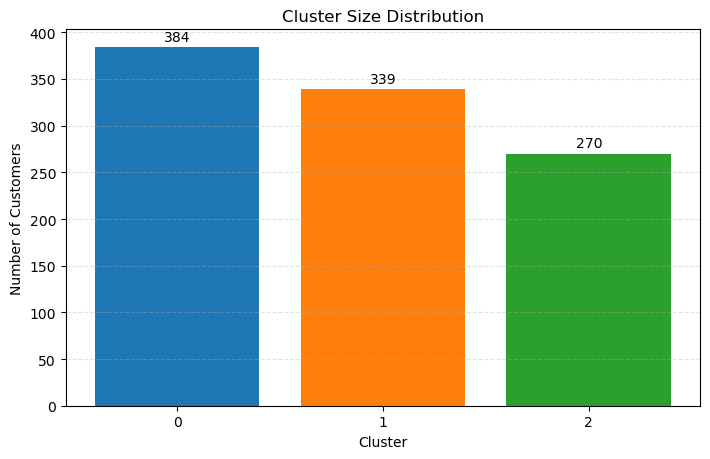


CLUSTER SIZE DISTRIBUTION
Cluster 0: 384 customers (38.7%)
Cluster 1: 339 customers (34.1%)
Cluster 2: 270 customers (27.2%)


In [15]:
# =========================
# 7B) Cluster size distribution (visual)
# =========================
cluster_counts = pd.Series(cluster_labels).value_counts().sort_index()

# Use the same cluster_colors from the PCA plot (fallback to tab10 if needed)
if "cluster_colors" not in globals():
    cmap = plt.get_cmap("tab10")
    cluster_colors = {cl: cmap(int(cl) % 10) for cl in sorted(cluster_counts.index.tolist())}

bar_colors = [cluster_colors[int(cl)] for cl in cluster_counts.index]

plt.figure(figsize=(7.2, 4.7))
plt.bar(cluster_counts.index.astype(str), cluster_counts.values, color=bar_colors)
plt.title("Cluster Size Distribution")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

# Data labels
for i, v in enumerate(cluster_counts.values):
    plt.text(i, v + max(cluster_counts.values)*0.01, str(int(v)), ha="center", va="bottom")

plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

# Print a quick cluster distribution summary
total_n = int(cluster_counts.sum())
print("\n" + "="*60)
print("CLUSTER SIZE DISTRIBUTION")
print("="*60)
for cl, n in cluster_counts.items():
    pct = (n / total_n * 100)
    print(f"Cluster {cl}: {int(n)} customers ({pct:.1f}%)")


## 8. Cluster Analysis and Initial Interpretation

### 8.1 Cluster Profiles (Descriptive Statistics)

We describe clusters using:
- **Size** of each cluster
- **Means / medians** of key behavioral features (spend, frequency, timing, transaction mix, tenure/recency, satisfaction)
- **Top differentiators**: features where a cluster is most above/below the dataset average


In [16]:
# =========================
# 8) Cluster profiling
# =========================

# Cluster sizes
cluster_sizes = df_clusters["cluster"].value_counts().sort_index()
cluster_sizes.name = "count"

# Mean profiles (numeric features)
cluster_means = df_clusters.groupby("cluster")[feature_cols].mean()
cluster_medians = df_clusters.groupby("cluster")[feature_cols].median()

# Add size to profile table
profiles = cluster_means.copy()
profiles.insert(0, "cluster_size", cluster_sizes)

display(profiles.head())

print("\nCluster size distribution:")
display(cluster_sizes.to_frame())

# Optional: income tier distribution per cluster (if available)
if income_group_col:
    print("\nIncome tier distribution by cluster:")
    tier_by_cluster = pd.crosstab(df_clusters["cluster"], df_clusters[income_group_col], normalize="index") * 100
    display(tier_by_cluster.round(1))


,cluster_size,total_spend,avg_spend,tenure_days,recency_days,pct_weekend_txn,pct_business_hours_txn,avg_txn_hour,count_type_bill_payment,count_type_investment,count_type_loan_payment,count_type_purchase,pct_tod_Afternoon,pct_tod_Evening,pct_tod_Morning,pct_tod_Night,high_risk_txn_count,pct_high_risk_txn,feedback_count,satisfaction_mean,ltr_mean
cluster,,,,,,,,,,,,,,,,,,,,,
0,384,18688.622396,2817.153880,158.234375,22.729167,0.284583,0.312396,11.362005,1.773438,1.617188,1.856771,1.570312,0.185000,0.165729,0.305078,0.343542,2.205729,0.347969,5.015625,5.601432,5.526641
1,339,8045.482301,2165.654159,107.064897,52.418879,0.287139,0.154808,11.029853,0.873156,0.970501,0.929204,1.026549,0.070029,0.201121,0.267994,0.460501,0.522124,0.156195,4.911504,5.517788,5.547581
2,270,9547.718519,2460.558000,113.118519,44.248148,0.266333,0.586926,12.369074,0.977778,1.085185,0.929630,1.059259,0.408704,0.107296,0.307926,0.175556,0.844444,0.238889,5.274074,5.696556,5.655963



Cluster size distribution:


,count
cluster,
0,384
1,339
2,270



Income tier distribution by cluster:


Income_Group,High,Low,Medium
cluster,,,
0,62.0,0.0,38.0
1,0.6,46.3,53.1
2,3.0,34.1,63.0


Key features to visualize: ['total_spend', 'txn_count', 'recency_days', 'tenure_days', 'avg_spend', 'satisfaction_mean', 'ltr_mean', 'pct_business_hours_txn', 'pct_weekend_txn', 'avg_txn_hour', 'count_type_loan_payment', 'count_type_investment', 'count_type_bill_payment', 'count_type_purchase']

OVERALL INSIGHT: Strongest separating features (higher score = clearer separation)


,feature,separation_score
0,total_spend,1.492503
1,pct_business_hours_txn,1.389899
2,txn_count,1.373148
3,tenure_days,0.954689
4,count_type_bill_payment,0.862753



Interpretation (overall):
- The clusters separate most clearly on: total_spend, pct_business_hours_txn, txn_count, tenure_days, count_type_bill_payment.
- In the box plots below, look for features where:
  • cluster medians are clearly apart, and
  • IQR boxes have limited overlap (cleaner separation).
- Note: for recency_days, LOWER values mean MORE recent/active (left-shift = healthier engagement).

FEATURE-LEVEL INSIGHTS (from box plots: median + spread + overlap cues)


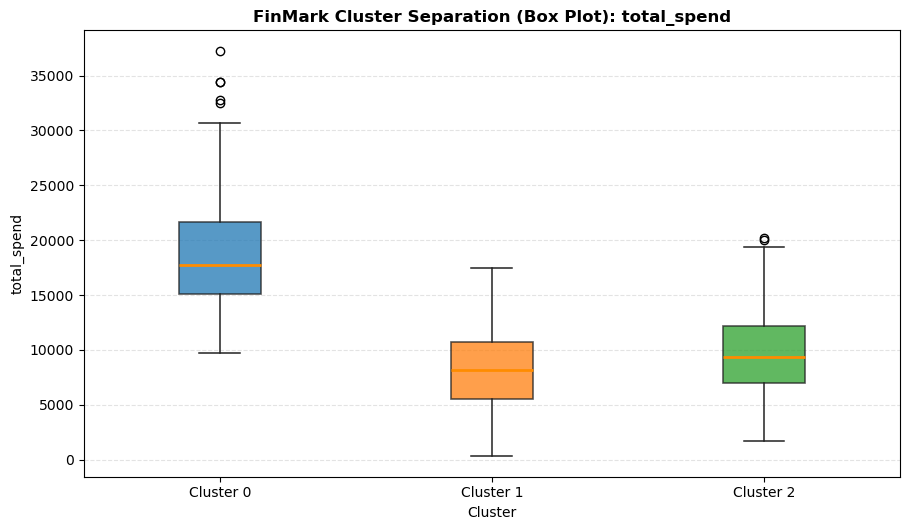


[total_spend]
- Clearer split cue: Cluster 0 has the highest median (17,712.00) vs Cluster 1 the lowest (8,128.00).
- Median spread (highest vs lowest median): 17,712.00 (C0) vs 8,128.00 (C1)
- Median-based separation score (range / overall std): 1.49  (higher = cleaner separation)
- Spread (IQR) per cluster: C0 IQR=6,611.75, C1 IQR=5,219.00, C2 IQR=5,186.00
- Reading cue: less IQR overlap + farther-apart medians = stronger segment distinction.


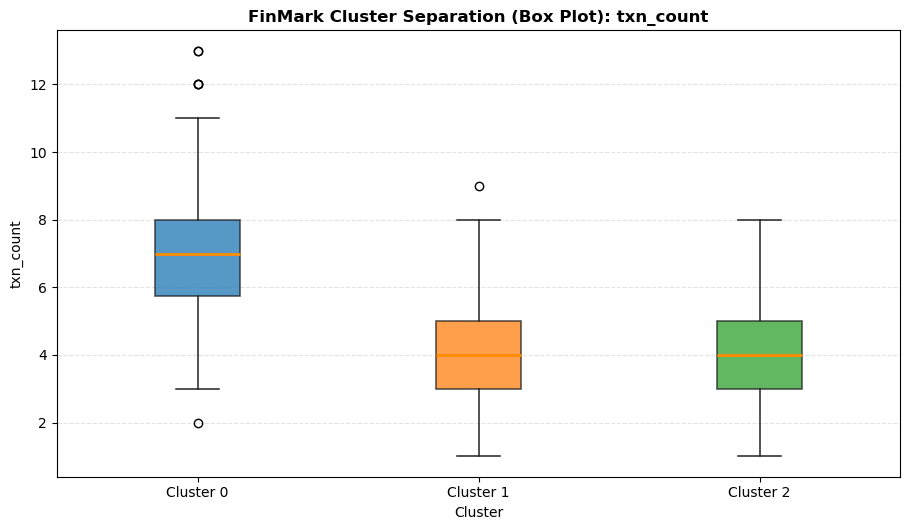


[txn_count]
- Clearer split cue: Cluster 0 has the highest median (7.00) vs Cluster 1 the lowest (4.00).
- Median spread (highest vs lowest median): 7.00 (C0) vs 4.00 (C1)
- Median-based separation score (range / overall std): 1.37  (higher = cleaner separation)
- Spread (IQR) per cluster: C0 IQR=2.25, C1 IQR=2.00, C2 IQR=2.00
- Reading cue: less IQR overlap + farther-apart medians = stronger segment distinction.


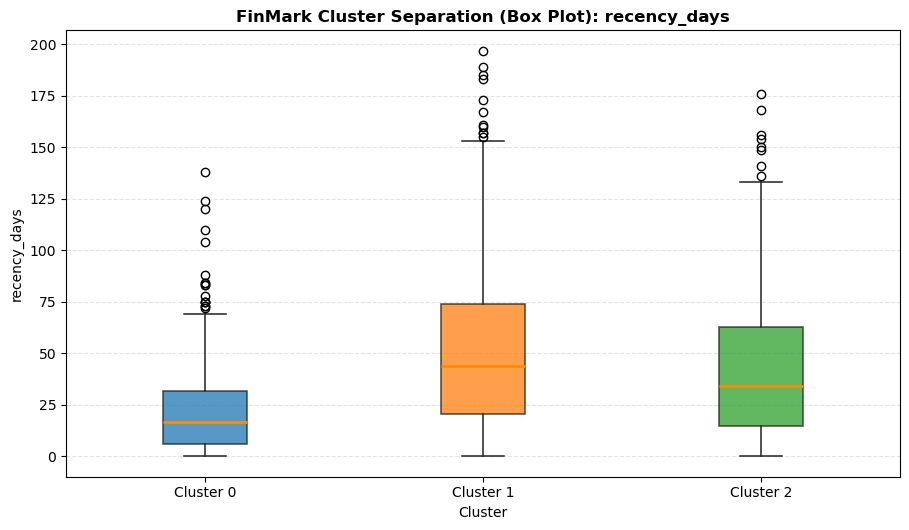


[recency_days]
- Clearer split cue: Cluster 1 has the highest median (44.00) vs Cluster 0 the lowest (16.50).
- Median spread (highest vs lowest median): 44.00 (C1) vs 16.50 (C0)
- Median-based separation score (range / overall std): 0.76  (higher = cleaner separation)
- Spread (IQR) per cluster: C0 IQR=26.00, C1 IQR=53.50, C2 IQR=47.75
- Interpretation tip: lower recency_days = more recent activity (lower median => more active segment).
- Reading cue: less IQR overlap + farther-apart medians = stronger segment distinction.


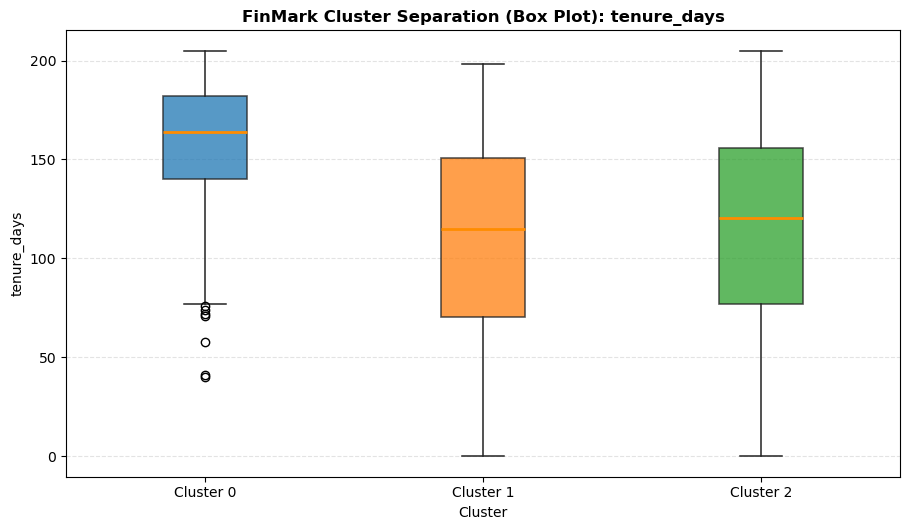


[tenure_days]
- Clearer split cue: Cluster 0 has the highest median (164.00) vs Cluster 1 the lowest (115.00).
- Median spread (highest vs lowest median): 164.00 (C0) vs 115.00 (C1)
- Median-based separation score (range / overall std): 0.95  (higher = cleaner separation)
- Spread (IQR) per cluster: C0 IQR=42.00, C1 IQR=80.50, C2 IQR=78.50
- Reading cue: less IQR overlap + farther-apart medians = stronger segment distinction.


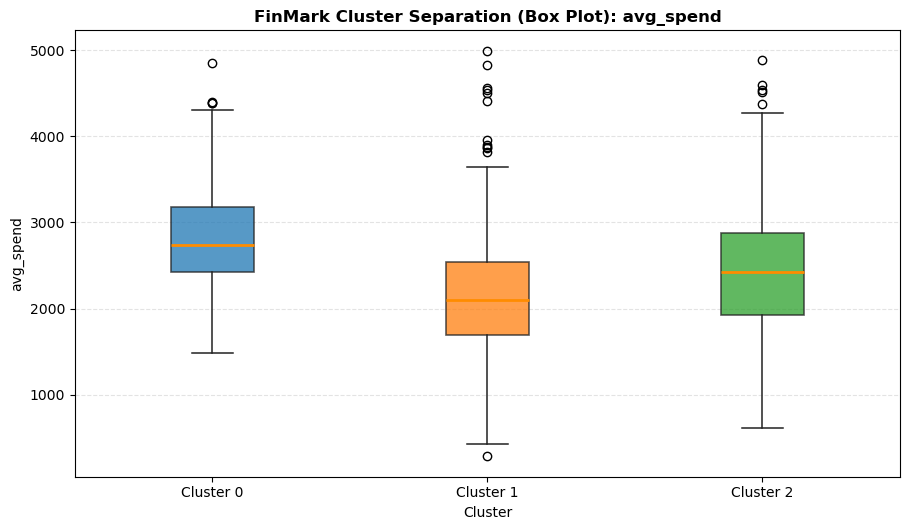


[avg_spend]
- Clearer split cue: Cluster 0 has the highest median (2,737.06) vs Cluster 1 the lowest (2,103.00).
- Median spread (highest vs lowest median): 2,737.06 (C0) vs 2,103.00 (C1)
- Median-based separation score (range / overall std): 0.84  (higher = cleaner separation)
- Spread (IQR) per cluster: C0 IQR=755.30, C1 IQR=849.19, C2 IQR=955.27
- Reading cue: less IQR overlap + farther-apart medians = stronger segment distinction.


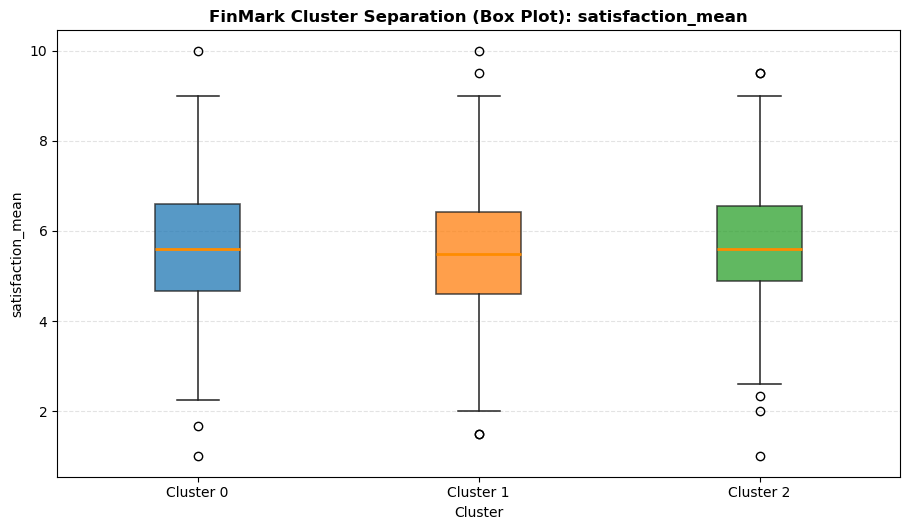


[satisfaction_mean]
- Clearer split cue: Cluster 0 has the highest median (5.60) vs Cluster 1 the lowest (5.50).
- Median spread (highest vs lowest median): 5.60 (C0) vs 5.50 (C1)
- Median-based separation score (range / overall std): 0.07  (higher = cleaner separation)
- Spread (IQR) per cluster: C0 IQR=1.93, C1 IQR=1.83, C2 IQR=1.65
- Reading cue: less IQR overlap + farther-apart medians = stronger segment distinction.


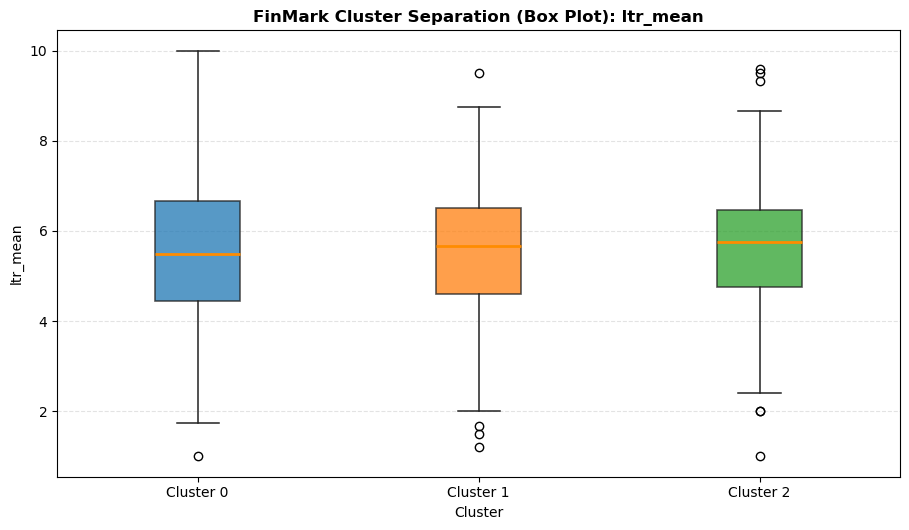


[ltr_mean]
- Clearer split cue: Cluster 2 has the highest median (5.75) vs Cluster 0 the lowest (5.50).
- Median spread (highest vs lowest median): 5.75 (C2) vs 5.50 (C0)
- Median-based separation score (range / overall std): 0.17  (higher = cleaner separation)
- Spread (IQR) per cluster: C0 IQR=2.23, C1 IQR=1.90, C2 IQR=1.72
- Reading cue: less IQR overlap + farther-apart medians = stronger segment distinction.


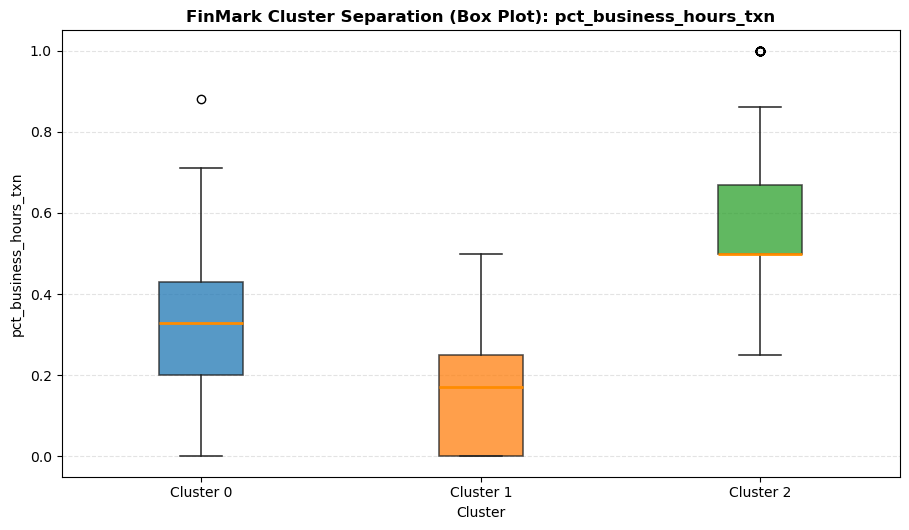


[pct_business_hours_txn]
- Clearer split cue: Cluster 2 has the highest median (0.50) vs Cluster 1 the lowest (0.17).
- Median spread (highest vs lowest median): 0.50 (C2) vs 0.17 (C1)
- Median-based separation score (range / overall std): 1.39  (higher = cleaner separation)
- Spread (IQR) per cluster: C0 IQR=0.23, C1 IQR=0.25, C2 IQR=0.17
- Reading cue: less IQR overlap + farther-apart medians = stronger segment distinction.


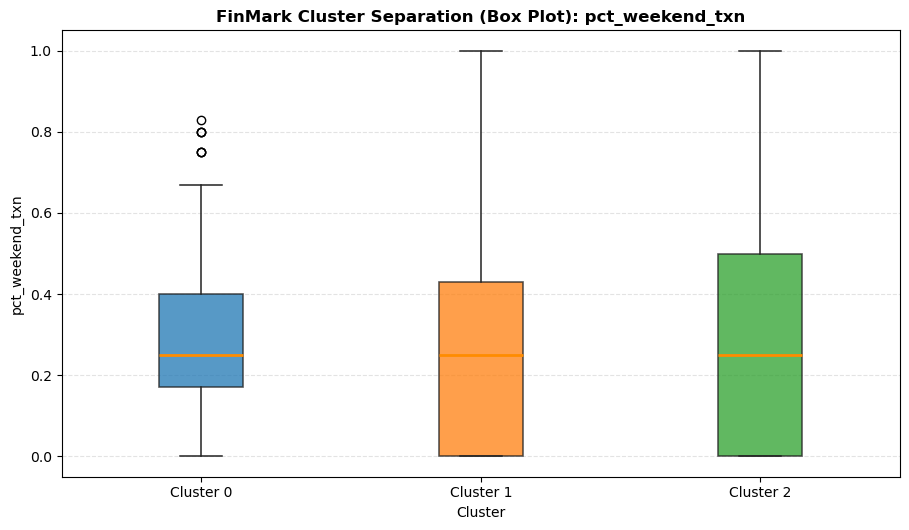


[pct_weekend_txn]
- Minimal median separation — this feature does NOT strongly distinguish clusters by itself.
- Median spread (highest vs lowest median): 0.25 (C0) vs 0.25 (C0)
- Median-based separation score (range / overall std): 0.00  (higher = cleaner separation)
- Spread (IQR) per cluster: C0 IQR=0.23, C1 IQR=0.43, C2 IQR=0.50
- Reading cue: less IQR overlap + farther-apart medians = stronger segment distinction.


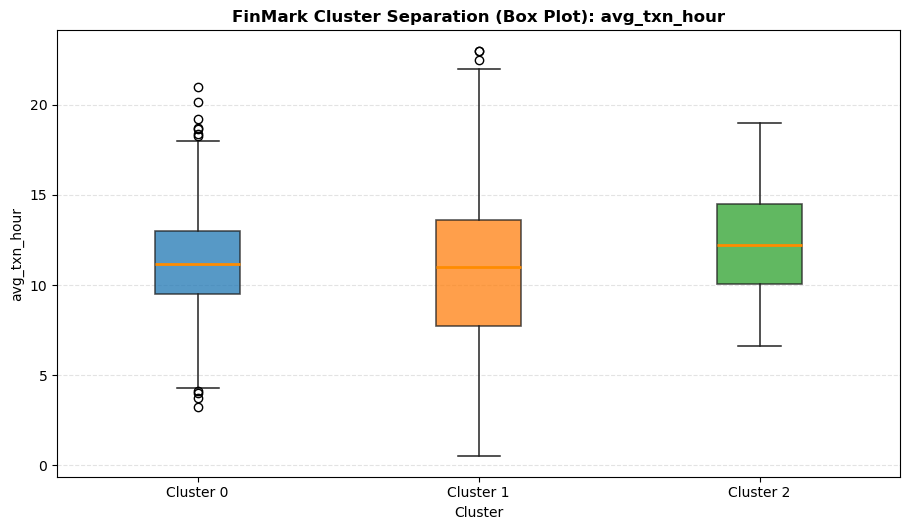


[avg_txn_hour]
- Clearer split cue: Cluster 2 has the highest median (12.22) vs Cluster 1 the lowest (11.00).
- Median spread (highest vs lowest median): 12.22 (C2) vs 11.00 (C1)
- Median-based separation score (range / overall std): 0.34  (higher = cleaner separation)
- Spread (IQR) per cluster: C0 IQR=3.50, C1 IQR=5.90, C2 IQR=4.45
- Reading cue: less IQR overlap + farther-apart medians = stronger segment distinction.


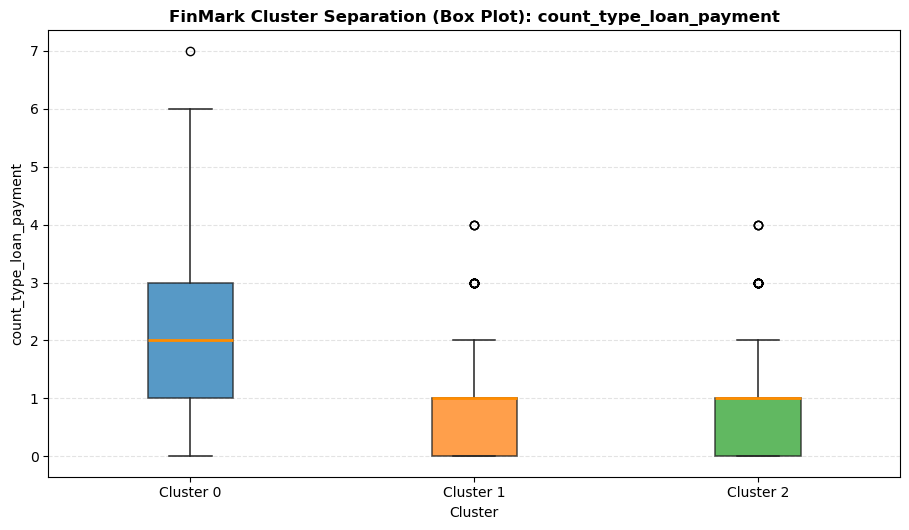


[count_type_loan_payment]
- Clearer split cue: Cluster 0 has the highest median (2.00) vs Cluster 1 the lowest (1.00).
- Median spread (highest vs lowest median): 2.00 (C0) vs 1.00 (C1)
- Median-based separation score (range / overall std): 0.86  (higher = cleaner separation)
- Spread (IQR) per cluster: C0 IQR=2.00, C1 IQR=1.00, C2 IQR=1.00
- Reading cue: less IQR overlap + farther-apart medians = stronger segment distinction.


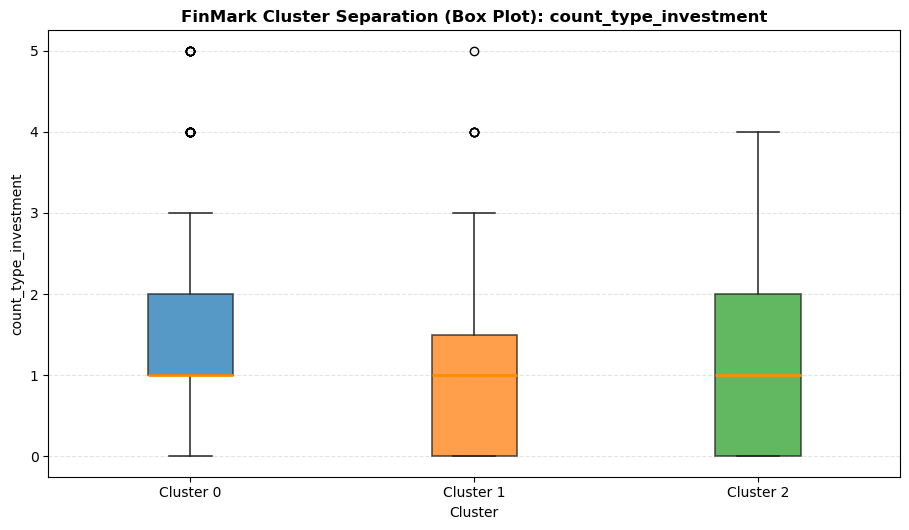


[count_type_investment]
- Minimal median separation — this feature does NOT strongly distinguish clusters by itself.
- Median spread (highest vs lowest median): 1.00 (C0) vs 1.00 (C0)
- Median-based separation score (range / overall std): 0.00  (higher = cleaner separation)
- Spread (IQR) per cluster: C0 IQR=1.00, C1 IQR=1.50, C2 IQR=2.00
- Reading cue: less IQR overlap + farther-apart medians = stronger segment distinction.


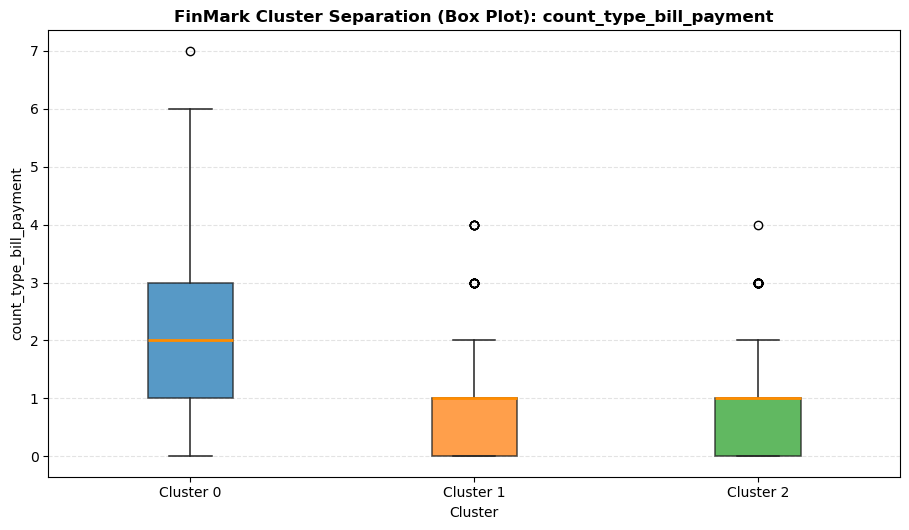


[count_type_bill_payment]
- Clearer split cue: Cluster 0 has the highest median (2.00) vs Cluster 1 the lowest (1.00).
- Median spread (highest vs lowest median): 2.00 (C0) vs 1.00 (C1)
- Median-based separation score (range / overall std): 0.86  (higher = cleaner separation)
- Spread (IQR) per cluster: C0 IQR=2.00, C1 IQR=1.00, C2 IQR=1.00
- Reading cue: less IQR overlap + farther-apart medians = stronger segment distinction.


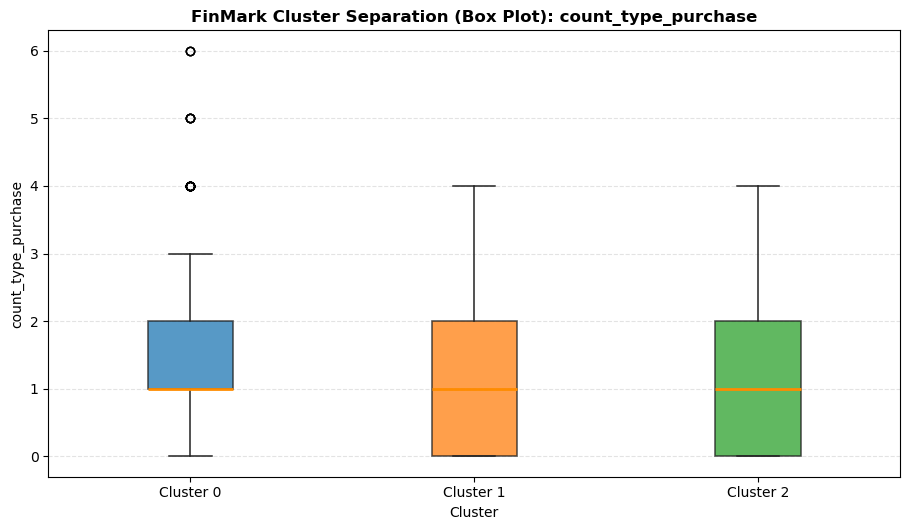


[count_type_purchase]
- Minimal median separation — this feature does NOT strongly distinguish clusters by itself.
- Median spread (highest vs lowest median): 1.00 (C0) vs 1.00 (C0)
- Median-based separation score (range / overall std): 0.00  (higher = cleaner separation)
- Spread (IQR) per cluster: C0 IQR=1.00, C1 IQR=2.00, C2 IQR=2.00
- Reading cue: less IQR overlap + farther-apart medians = stronger segment distinction.


total_spend                    txn_count               recency_days                tenure_days                avg_spend            \
               mean   median       std      mean median    std         mean median     std        mean median     std      mean    median   
cluster                                                                                                                                     
0         18688.622  17712.0  4811.189     6.818    7.0  1.835       22.729   16.5  22.464     158.234  164.0  30.974  2817.154  2737.055   
1          8045.482   8128.0  3583.458     3.799    4.0  1.548       52.419   44.0  41.181     107.065  115.0  53.777  2165.654  2103.000   
2          9547.719   9392.5  3835.981     4.052    4.0  1.544       44.248   34.0  37.466     113.119  120.5  51.441  2460.558  2420.500   

                 satisfaction_mean               ltr_mean               pct_business_hours_txn               pct_weekend_txn         \
             std              mean median    std     mean median    std                   mean median    std            mean median   
cluster                                                                                                                               
0        587.196             5.601  5.600  1.411    5.527   5.50  1.568                  0.312   0.33  0.165           0.285   0.25   
1        740.938             5.518  5.500  1.419    5.548   5.67  1.432                  0.155   0.17  0.156           0.287   0.25   
2        808.079             5.697  5.595  1.403    5.656   5.75  1.359                  0.587   0.50  0.182           0.266   0.25   

               avg_txn_hour                count_type_loan_payment               count_type_investment                \
           std         mean  median    std                    mean median    std                  mean median    std   
cluster                                                                                                                
0        0.182       11.362  11.155  2.893                   1.857    2.0  1.276                 1.617    1.0  1.162   
1        0.250       11.030  11.000  4.649                   0.929    1.0  0.904                 0.971    1.0  0.954   
2        0.246       12.369  12.225  2.915                   0.930    1.0  0.932                 1.085    1.0  0.935   

        count_type_bill_payment               count_type_purchase                
                           mean median    std                mean median    std  
cluster                                                                          
0                         1.773    2.0  1.265               1.570    1.0  1.185  
1                         0.873    1.0  0.935               1.027    1.0  0.934  
2                         0.978    1.0  0.968               1.059    1.0  0.907


END OF CLUSTER SEPARATION (BOX PLOTS) + INSIGHTS


In [17]:
# ===========================
# 8B) Cluster separation on key business features (+ insights prints)
# ===========================
# Visualization approach: BOX PLOTS (cleaner + easier to compare medians/IQR across clusters)
# Enhancements requested:
# 1) Box plot colors match cluster colors used in the PCA clustering scatter plot
# 2) Add stronger, data-driven interpretation prints after each plot (median/IQR/overlap cues)

# --- Safety: ensure df_clusters exists (in case cells are run out of order) ---
if "df_clusters" not in globals():
    # Try to reconstruct from earlier artifacts
    _base = df.copy() if "df" in globals() else None

    # Resolve / reconstruct cluster_labels
    _labels = cluster_labels if "cluster_labels" in globals() else None

    if _labels is None:
        for _name in ["kmeans_final", "kmeans", "kmeans_model"]:
            if _name in globals():
                _km = globals()[_name]
                if hasattr(_km, "labels_"):
                    _labels = _km.labels_
                elif "X_pca" in globals():
                    _labels = _km.predict(X_pca)
                break

    if _base is None or _labels is None:
        raise NameError(
            "df_clusters is not defined. Please run earlier cells that load the dataset and create cluster_labels/df_clusters "
            "(the cells that build X_pca and fit KMeans)."
        )

    df_clusters = _base.copy()
    df_clusters["cluster"] = _labels

# --- Helper: pick the first existing column name from candidates
def pick_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

# --- Resolve key columns robustly (handles minor naming differences)
total_spend_col  = pick_col(df_clusters, ["total_spend", "Total_Spend", "totalSpend"])
txn_count_col    = pick_col(df_clusters, ["txn_count", "txns_count", "transaction_count", "Transaction_Count"])
recency_col      = pick_col(df_clusters, ["recency_days", "recency", "days_since_last_txn", "Recency_Days"])
tenure_col       = pick_col(df_clusters, ["tenure_days", "tenure", "customer_tenure_days", "Tenure_Days"])
avg_spend_col    = pick_col(df_clusters, ["avg_spend", "avg_txn_amount", "average_spend", "Avg_Spend"])
satisfaction_col = pick_col(df_clusters, ["satisfaction_mean", "avg_satisfaction", "satisfaction", "Satisfaction_Mean"])
ltr_col          = pick_col(df_clusters, ["ltr_mean", "LTR_Mean", "likelihood_to_recommend", "nps"])

# --- Preferred list (only keep what exists)
preferred = [
    total_spend_col,
    txn_count_col,
    recency_col,
    tenure_col,
    avg_spend_col,
    satisfaction_col,
    ltr_col,
    "pct_business_hours_txn",
    "pct_weekend_txn",
    "avg_txn_hour",
    "count_type_loan_payment",
    "count_type_investment",
    "count_type_bill_payment",
    "count_type_purchase",
]
key_features = [c for c in preferred if c and c in df_clusters.columns]

# Fallback if list becomes too small
if len(key_features) < 5:
    numeric_cols = df_clusters.select_dtypes(include=[np.number]).columns.tolist()
    key_features = [c for c in numeric_cols if c not in ["cluster"]][:8]

clusters = sorted(df_clusters["cluster"].unique())
print("Key features to visualize:", key_features)

# =========================
# Build cluster color map (match the PCA clustering scatter colors)
# =========================
# If you already have `cluster_colors` defined earlier, we reuse it. Otherwise we recreate it.
if "cluster_colors" in globals() and isinstance(cluster_colors, dict) and all(k in cluster_colors for k in clusters):
    _cluster_colors = cluster_colors
else:
    cmap = plt.get_cmap("tab10")
    _cluster_colors = {cl: cmap(int(cl) % 10) for cl in clusters}

# --------------------------
# A) OVERALL INSIGHT: which features separate clusters the most? (median-based + robust)
# --------------------------
def _safe_std(s):
    v = float(np.nanstd(s.values))
    return v if v > 0 else np.nan

overall_stds = df_clusters[key_features].apply(_safe_std)

# Separation score (median-based): (max median - min median) / overall std
sep_scores = []
for feat in key_features:
    meds = df_clusters.groupby("cluster")[feat].median(numeric_only=False)
    if meds.isna().all():
        continue
    rng = float(meds.max() - meds.min())
    denom = float(overall_stds.get(feat, np.nan))
    score = (rng / denom) if (denom and not np.isnan(denom)) else rng
    sep_scores.append([feat, score])

sep_tbl = pd.DataFrame(sep_scores, columns=["feature", "separation_score"]).sort_values(
    "separation_score", ascending=False
).reset_index(drop=True)

top_sep_n = min(5, len(sep_tbl))
print("\n" + "="*92)
print("OVERALL INSIGHT: Strongest separating features (higher score = clearer separation)")
print("="*92)
display(sep_tbl.head(top_sep_n))

print("\nInterpretation (overall):")
if top_sep_n > 0:
    top_feats = sep_tbl.head(top_sep_n)["feature"].tolist()
    print(f"- The clusters separate most clearly on: {', '.join(top_feats)}.")
print("- In the box plots below, look for features where:")
print("  • cluster medians are clearly apart, and")
print("  • IQR boxes have limited overlap (cleaner separation).")
if recency_col:
    print(f"- Note: for {recency_col}, LOWER values mean MORE recent/active (left-shift = healthier engagement).")

# --------------------------
# Helper functions for per-feature print insights
# --------------------------
def fmt(x, nd=2):
    try:
        if pd.isna(x): return "NA"
        return f"{float(x):,.{nd}f}"
    except Exception:
        return str(x)

def iqr(a):
    a = pd.Series(a).dropna()
    if len(a) == 0:
        return np.nan
    return float(a.quantile(0.75) - a.quantile(0.25))

def median_sep_score(feat):
    meds = df_clusters.groupby("cluster")[feat].median()
    rng = float(meds.max() - meds.min())
    denom = float(overall_stds.get(feat, np.nan))
    return (rng / denom) if (denom and not np.isnan(denom)) else rng

def describe_feature_from_boxplot(feat):
    # Cluster medians and IQRs
    meds = df_clusters.groupby("cluster")[feat].median()
    iqrs = {cl: iqr(df_clusters.loc[df_clusters["cluster"] == cl, feat]) for cl in clusters}

    # Identify highest/lowest median clusters
    hi_cl = int(meds.idxmax())
    lo_cl = int(meds.idxmin())
    med_spread = float(meds.max() - meds.min())
    score = float(median_sep_score(feat))

    # Feature-specific note
    note = ""
    if recency_col and feat == recency_col:
        note = f"Interpretation tip: lower {recency_col} = more recent activity (lower median => more active segment)."

    # If medians basically tie, call it out
    if np.isclose(med_spread, 0.0, atol=1e-9):
        headline = "Minimal median separation — this feature does NOT strongly distinguish clusters by itself."
    else:
        headline = (
            f"Clearer split cue: Cluster {hi_cl} has the highest median ({fmt(meds[hi_cl])}) "
            f"vs Cluster {lo_cl} the lowest ({fmt(meds[lo_cl])})."
        )

    # IQR summary string
    iqr_str = ", ".join([f"C{cl} IQR={fmt(iqrs[cl])}" for cl in clusters])

    print(f"\n[{feat}]")
    print(f"- {headline}")
    print(f"- Median spread (highest vs lowest median): {fmt(meds[hi_cl])} (C{hi_cl}) vs {fmt(meds[lo_cl])} (C{lo_cl})")
    print(f"- Median-based separation score (range / overall std): {fmt(score)}  (higher = cleaner separation)")
    print(f"- Spread (IQR) per cluster: {iqr_str}")
    if note:
        print(f"- {note}")
    print("- Reading cue: less IQR overlap + farther-apart medians = stronger segment distinction.")

# --------------------------
# B) BOX PLOTS: per-feature cluster separation (colored per cluster)
# --------------------------
print("\n" + "="*92)
print("FEATURE-LEVEL INSIGHTS (from box plots: median + spread + overlap cues)")
print("="*92)

for feat in key_features:
    # Gather data per cluster in the correct order
    data = [df_clusters.loc[df_clusters["cluster"] == cl, feat].dropna().values for cl in clusters]

    # Skip empty features
    if all(len(d) == 0 for d in data):
        continue

    plt.figure(figsize=(9.2, 5.4))
    bp = plt.boxplot(
        data,
        labels=[f"Cluster {cl}" for cl in clusters],
        patch_artist=True,
        showfliers=True
    )

    # Color each cluster box to match cluster colors
    for patch, cl in zip(bp["boxes"], clusters):
        patch.set_facecolor(_cluster_colors[cl])
        patch.set_alpha(0.75)
        patch.set_edgecolor("#222222")
        patch.set_linewidth(1.2)

    # Style whiskers/caps/medians (keep readable)
    for w in bp["whiskers"]:
        w.set_color("#222222"); w.set_linewidth(1.1)
    for c in bp["caps"]:
        c.set_color("#222222"); c.set_linewidth(1.1)
    for m in bp["medians"]:
        m.set_color("#ff8c00"); m.set_linewidth(2.0)  # median line accent

    plt.title(f"FinMark Cluster Separation (Box Plot): {feat}", fontweight="bold")
    plt.xlabel("Cluster")
    plt.ylabel(feat)
    plt.grid(axis="y", linestyle="--", alpha=0.35)
    plt.tight_layout()
    plt.show()

    # Data-driven insights (computed from the current box plot distributions)
    describe_feature_from_boxplot(feat)

# --------------------------
# C) QUICK STATS TABLE (optional)
# --------------------------
display(
    df_clusters.groupby("cluster")[key_features]
    .agg(["mean", "median", "std"])
    .round(3)
)

print("\n" + "="*92)
print("END OF CLUSTER SEPARATION (BOX PLOTS) + INSIGHTS")
print("="*92)

### 8B) Cluster Separation on Key Business Features — Interpretation Notes (Box Plots)

Below are short, stakeholder-friendly interpretations for each **box plot** in Section 8B.  
**How to read:** The **median line** shows the “typical” value per cluster, while the **box (IQR)** shows the middle spread. Less overlap between boxes = clearer separation.

---

#### 1) **Total Spend (`total_spend`)**
There is a **clear value hierarchy** across clusters. **Cluster 0** shows the **highest typical (median) total spend**, while **Cluster 1** has the **lowest spend**, and **Cluster 2** sits in-between. This confirms that **customer value (monetary contribution)** is a major driver of segmentation.

---

#### 2) **Transaction Frequency (`txn_count`)**
Frequency strongly separates the groups: **Cluster 0** has the **highest median transaction count**, indicating the most consistent engagement, while **Clusters 1 and 2** are noticeably lower. This suggests Cluster 0 behaves like the **core usage base**, whereas Clusters 1 and 2 represent **lighter engagement patterns**.

---

#### 3) **Recency (`recency_days`)** *(lower = more recent activity)*
Recency highlights churn/engagement risk differences. **Cluster 0** shows the **lowest recency median** (most recently active), while **Cluster 1** has the **highest recency median** (least recent activity), indicating higher churn risk. **Cluster 2** falls between them, showing moderate recency.

---

#### 4) **Tenure (`tenure_days`)**
Tenure separates customer maturity/relationship depth. **Cluster 0** generally shows **higher tenure medians**, reflecting longer customer relationships, while **Clusters 1 and 2** are comparatively lower/less consistent. This supports Cluster 0 being more “established” customers.

---

#### 5) **Average Spend per Transaction (`avg_spend`)**
Average transaction value differs across clusters, with **Cluster 0** typically showing **higher median average spend** than **Cluster 1**, and **Cluster 2** landing around mid-range. This indicates Cluster 0 contributes both through **higher engagement and stronger average ticket size**.

---

#### 6) **Satisfaction (`satisfaction_mean`)**
Satisfaction shows **heavy overlap** across clusters (medians are close), meaning customer experience scores are **not the main separator** of segments here. This is still useful insight: even lower-value or at-risk groups may have similar satisfaction levels, so behavior (spend/recency/frequency) is doing most of the clustering work.

---

#### 7) **Likelihood to Recommend (`ltr_mean`)**
LTR also shows **moderate-to-high overlap** between clusters. Differences exist, but they are **not as strong** as monetary/behavior signals. This suggests advocacy may require **separate targeting** (CX programs) rather than being assumed from spend alone.

---

#### 8) **Business-Hours Activity Share (`pct_business_hours_txn`)**
This feature provides one of the **clearest behavioral separations**. **Cluster 2** shows the **highest median business-hours share**, while **Cluster 1** is much lower (often near zero), and **Cluster 0** sits in between. This is actionable for campaign timing: Cluster 2 is best reached during **weekday/daytime**, while Cluster 1 likely responds better outside business hours.

---

#### 9) **Weekend Activity Share (`pct_weekend_txn`)**
Weekend share shows **limited median separation** (medians are very similar), but the **spread differs** across clusters (some clusters show wider ranges). This indicates weekend behavior is not a strong primary separator, but may still help refine messaging or scheduling for a subset of customers.

---

#### 10) **Average Transaction Hour (`avg_txn_hour`)**
The clusters show some timing differences in transaction hours, but separation is **moderate** (with some overlap). **Cluster 2** trends toward a slightly later median hour compared to others, suggesting distinct timing preferences that can inform notification windows.

---

#### 11) **Loan-Payment Count (`count_type_loan_payment`)**
This feature distinguishes **financial behavior mix**. **Cluster 0** generally shows a **higher median** for loan-payment activity, while Clusters 1 and 2 are lower. This suggests Cluster 0 engages more with loan-related transactions and can be targeted with loan service features or offers.

---

#### 12) **Investment Count (`count_type_investment`)**
Investment activity shows **very small median differences** across clusters (often same or near-same), meaning it is not a strong standalone separator. However, variation in spread suggests a subset of customers within clusters may still be investment-active.

---

#### 13) **Bill-Payment Count (`count_type_bill_payment`)**
Similar to loan payments, this feature shows **clearer separation** with **Cluster 0** typically higher than the others. This supports a “utility payer / routine transaction” behavior for Cluster 0, which can help tailor product bundles or reminders.

---

#### 14) **Purchase Count (`count_type_purchase`)**
Purchase counts show **minimal median separation** (often similar medians), indicating that pure purchase volume is not the key differentiator here compared to total spend and transaction frequency. This can mean customers differ more in “value per engagement” than in purchase counts alone.

---

### Quick takeaway
Overall, the box plots confirm that FinMark’s clusters are primarily driven by **behavioral value signals** (total spend, transaction frequency, recency) and **timing behavior** (business-hours share), while **experience signals** (satisfaction and LTR) show heavier overlap and appear less responsible for segmentation. This supports using these segments for **targeting, retention prioritization, and campaign timing**, with separate follow-up analysis for CX improvement initiatives.

In [18]:
# =========================
# 8C) Statistical validation: Do clusters differ on key variables?
# =========================
# We run one-way ANOVA (F-test) per feature across clusters to validate that
# cluster means differ more than expected by chance.

from scipy.stats import f_oneway

# --- Safety: ensure df_clusters and key_features exist ---
# --- Safety: ensure df_clusters exists (in case cells are run out of order) ---
if "df_clusters" not in globals():
    # Try to reconstruct from earlier artifacts
    if "df" in globals():
        _base = df.copy()
    else:
        _base = None

    # Resolve / reconstruct cluster_labels
    if "cluster_labels" in globals():
        _labels = cluster_labels
    else:
        _labels = None
        # Try to pull labels from an existing trained model
        for _name in ["kmeans_final", "kmeans", "kmeans_model"]:
            if _name in globals():
                _km = globals()[_name]
                if hasattr(_km, "labels_"):
                    _labels = _km.labels_
                elif "X_pca" in globals():
                    _labels = _km.predict(X_pca)
                break

    if _base is None or _labels is None:
        raise NameError(
            "df_clusters is not defined. Please run the earlier cells that load the dataset and create cluster_labels/df_clusters "
            "(the cells that build X_pca and fit KMeans)."
        )

    df_clusters = _base.copy()
    df_clusters["cluster"] = _labels

    # Optional PCA columns for convenience (if available)
    if "X_pca" in globals() and isinstance(X_pca, (np.ndarray,)):
        if X_pca.shape[1] >= 2:
            df_clusters["PC1"] = X_pca[:, 0]
            df_clusters["PC2"] = X_pca[:, 1]

if "key_features" not in globals():
    # Fallback: test all numeric business columns (exclude identifiers and cluster/meta columns)
    exclude = {"customer_id", "cluster", "cluster_name", "PC1", "PC2"}
    key_features = [c for c in df_clusters.select_dtypes(include=[np.number]).columns if c not in exclude]

anova_rows = []
clusters = sorted(df_clusters["cluster"].unique())

for feat in key_features:
    groups = [df_clusters.loc[df_clusters["cluster"] == k, feat].dropna() for k in clusters]
    # need at least 2 values per group for a stable test
    if all(len(g) >= 2 for g in groups):
        F, p = f_oneway(*groups)

        # effect size (eta-squared): between-group variance / total variance
        overall_mean = df_clusters[feat].mean()
        ss_between = sum(len(g) * (g.mean() - overall_mean) ** 2 for g in groups)
        ss_total = ((df_clusters[feat] - overall_mean) ** 2).sum()
        eta2 = float(ss_between / ss_total) if ss_total > 0 else np.nan

        conclusion = "Significant differences exist" if p < 0.05 else "No significant difference"
        anova_rows.append([feat, float(F), float(p), eta2, conclusion])

anova_df = pd.DataFrame(anova_rows, columns=["feature", "F_statistic", "p_value", "eta_squared", "conclusion"])
anova_df = anova_df.sort_values("p_value").reset_index(drop=True)

print("ANOVA results (sorted by p-value):")
display(anova_df)

sig_05 = (anova_df["p_value"] < 0.05).sum()
print(f"Significant features at p < 0.05: {sig_05} / {len(anova_df)}")

ANOVA results (sorted by p-value):


,feature,F_statistic,p_value,eta_squared,conclusion
0,total_spend,685.855745,1.236329e-187,0.580812,Significant differences exist
1,pct_business_hours_txn,507.448774,2.012750e-152,0.506209,Significant differences exist
2,txn_count,360.998760,1.800410e-118,0.421728,Significant differences exist
3,tenure_days,134.570796,2.006824e-52,0.213750,Significant differences exist
4,count_type_loan_payment,88.482116,4.425238e-36,0.151645,Significant differences exist
5,avg_spend,77.205926,6.936805e-32,0.134927,Significant differences exist
6,count_type_bill_payment,73.932610,1.187036e-30,0.129950,Significant differences exist
7,recency_days,73.578754,1.615150e-30,0.129408,Significant differences exist
8,count_type_investment,39.987466,1.992911e-17,0.074745,Significant differences exist
9,count_type_purchase,31.059700,8.264794e-14,0.059042,Significant differences exist


Significant features at p < 0.05: 11 / 14


In [19]:
# =========================
# 9) Name clusters (business-friendly) + definitions + recommendations
# =========================

def pick_existing(cols, df):
    for c in cols:
        if c in df.columns:
            return c
    return None

# --- Robust column picks ---
money_col = pick_existing(["total_spend", "Total_Spend", "monetary", "monetary_value"], df_clusters)
freq_col  = pick_existing(["txn_count", "Transaction_Count", "frequency", "freq"], df_clusters)
rec_col   = pick_existing(["recency_days", "Recency_Days", "recency"], df_clusters)
sat_col   = pick_existing(["satisfaction_mean", "Satisfaction_Mean", "satisfaction_score", "satisfaction"], df_clusters)
ltr_col   = pick_existing(["ltr_mean", "LTR_Mean", "likelihood_to_recommend", "nps"], df_clusters)

# Always keep these keys if present (for printing)
print_cols = [c for c in [money_col, freq_col, rec_col, sat_col, ltr_col] if c is not None]
print("Core naming/summary columns:", print_cols)

# --- Cluster-level averages (for naming logic + print summaries) ---
cent = df_clusters.groupby("cluster")[print_cols].mean(numeric_only=True)

def q(series, p):
    return float(series.quantile(p))

# 33/66 quantile bands (robust to outliers)
money_q1, money_q3 = (q(df_clusters[money_col], 0.33), q(df_clusters[money_col], 0.66)) if money_col else (None, None)
freq_q1,  freq_q3  = (q(df_clusters[freq_col],  0.33), q(df_clusters[freq_col],  0.66)) if freq_col  else (None, None)
rec_q1,   rec_q3   = (q(df_clusters[rec_col],   0.33), q(df_clusters[rec_col],   0.66)) if rec_col   else (None, None)
sat_q1,   sat_q3   = (q(df_clusters[sat_col],   0.33), q(df_clusters[sat_col],   0.66)) if sat_col   else (None, None)

def band(v, q1, q3, low_label, mid_label, high_label):
    if q1 is None or q3 is None or pd.isna(v):
        return mid_label
    if v >= q3: return high_label
    if v <= q1: return low_label
    return mid_label

# --- Previous naming convention (kept in parenthesis for reference) ---
# Uses the same core pillars but outputs a short, structured label.
def old_style_name(spend_band, freq_band, rec_band, sat_tone_short=""):
    base = f"{spend_band}-Value {freq_band} {rec_band}".replace("  ", " ").strip()
    return f"{base} {sat_tone_short}".strip()

cluster_names = {}
cluster_old_names = {}

for cl in cent.index:
    # Monetary + frequency
    spend_band = band(cent.loc[cl, money_col], money_q1, money_q3, "Low", "Mid", "High") if money_col else "Mid"
    freq_band  = band(cent.loc[cl, freq_col],  freq_q1,  freq_q3,  "Occasional", "Regular", "Frequent") if freq_col else "Regular"

    # Recency: lower is better (more active), so invert labeling
    if rec_col:
        r = cent.loc[cl, rec_col]
        if rec_q1 is None or rec_q3 is None or pd.isna(r):
            rec_band = "Warm"
        elif r <= rec_q1:
            rec_band = "Active"
        elif r >= rec_q3:
            rec_band = "At-Risk"
        else:
            rec_band = "Warm"
    else:
        rec_band = "Warm"

    # Satisfaction tone
    sat_tone = ""
    sat_tone_short = ""
    if sat_col:
        s = cent.loc[cl, sat_col]
        if sat_q1 is not None and sat_q3 is not None and not pd.isna(s):
            if s >= sat_q3:
                sat_tone = " (Satisfied)"
                sat_tone_short = "(High-Sat)"
            elif s <= sat_q1:
                sat_tone = " (Frustrated)"
                sat_tone_short = "(Low-Sat)"

    # --- Business-friendly persona names (rule-based but readable) ---
    # (Uses the same "story" as the cluster pillars)
    if spend_band == "High" and freq_band in ["Regular", "Frequent"] and rec_band in ["Active", "Warm"]:
        name = "Prime Value Loyalists"
    elif spend_band in ["Mid"] and freq_band in ["Regular"] and rec_band == "At-Risk":
        name = "Slipping Value Builders"
    elif spend_band == "Low" and rec_band == "At-Risk":
        name = "Dormant Budget Drifters"
    else:
        # fallback (still readable)
        name = f"{spend_band}-Value {freq_band} {rec_band}".replace("  ", " ").strip()

    cluster_names[int(cl)] = (name + sat_tone).strip()
    cluster_old_names[int(cl)] = old_style_name(spend_band, freq_band, rec_band, sat_tone_short)

print("\nCluster names (business-friendly):")
for k, v in cluster_names.items():
    print(f"  Cluster {k}: {v}   ({cluster_old_names[k]})")

# Attach names
df_clusters["cluster_name"] = df_clusters["cluster"].map(cluster_names)

# --- Helper: build a 1-sentence definition + recommendation from cluster stats ---
overall = df_clusters[print_cols].mean(numeric_only=True)

def fmt_num(x, kind="float", digits=2):
    if pd.isna(x): return "NA"
    if kind == "int": return f"{int(round(float(x))):,}"
    return f"{float(x):,.{digits}f}"

def build_definition_and_reco(row_mean, spend_band, freq_band, rec_band, sat_level):
    # 1-sentence definition
    definition = (
        f"Customers with {spend_band.lower()} overall value, {freq_band.lower()} usage, and {rec_band.lower()} engagement; "
        f"satisfaction is {sat_level.lower()}."
    )

    # Recommendations (actionable, segment-specific)
    if spend_band == "High" and rec_band in ["Active", "Warm"]:
        reco = (
            "Protect and grow: prioritize retention perks, proactive support, and personalized offers; "
            "promote premium add-ons and cross-sell based on transaction mix."
        )
    elif rec_band == "At-Risk" and spend_band in ["Mid", "High"]:
        reco = (
            "Prevent churn: trigger win-back campaigns (time-limited incentives), outreach from support, and friction audits; "
            "monitor recency weekly and intervene early."
        )
    elif rec_band == "At-Risk" and spend_band == "Low":
        reco = (
            "Low-cost reactivation: automate reminders, offer simple onboarding nudges, and test small incentives; "
            "focus on converting to steady usage without heavy spend."
        )
    else:
        reco = (
            "Nurture: reinforce habit-building (reminders/loyalty), reduce friction in common flows, "
            "and tailor messaging to the dominant transaction types."
        )

    # If satisfaction is low, layer service recovery actions
    if sat_level in ["Low", "Frustrated"]:
        reco = (
            "Service recovery first: identify pain points, prioritize resolution for common issues, and follow up after fixes. "
            + reco
        )

    return definition, reco

# --- Build printable report table (count + pct + key means) ---
cluster_counts = df_clusters["cluster"].value_counts().sort_index()
n_total = len(df_clusters)

report_rows = []
for cl in sorted(cluster_counts.index):
    sub = df_clusters[df_clusters["cluster"] == cl]
    means = sub[print_cols].mean(numeric_only=True)

    # Recompute bands for definition/reco text
    spend_band = band(means[money_col], money_q1, money_q3, "Low", "Mid", "High") if money_col else "Mid"
    freq_band  = band(means[freq_col],  freq_q1,  freq_q3,  "Occasional", "Regular", "Frequent") if freq_col else "Regular"

    if rec_col:
        r = means[rec_col]
        if rec_q1 is None or rec_q3 is None or pd.isna(r):
            rec_band = "Warm"
        elif r <= rec_q1:
            rec_band = "Active"
        elif r >= rec_q3:
            rec_band = "At-Risk"
        else:
            rec_band = "Warm"
    else:
        rec_band = "Warm"

    sat_level = "Mid"
    if sat_col and sat_q1 is not None and sat_q3 is not None and pd.notna(means[sat_col]):
        sat_level = "High" if means[sat_col] >= sat_q3 else ("Low" if means[sat_col] <= sat_q1 else "Mid")

    definition, reco = build_definition_and_reco(means, spend_band, freq_band, rec_band, sat_level)

    report_rows.append({
        "cluster": int(cl),
        "cluster_name": cluster_names[int(cl)],
        "old_name": cluster_old_names[int(cl)],
        "customers": int(cluster_counts.loc[cl]),
        "pct_customers": float(cluster_counts.loc[cl] / n_total * 100.0),
        "definition": definition,
        "recommendations": reco
    })

cluster_report = pd.DataFrame(report_rows).sort_values("cluster").reset_index(drop=True)

# --- Pretty console print (detailed) ---
print("\n" + "="*92)
print("CLUSTER REPORT (Names + Definitions + Key Metrics + Recommendations)")
print("="*92)

for _, row in cluster_report.iterrows():
    cl = int(row["cluster"])
    pct = row["pct_customers"]
    print("\n" + "-"*92)
    print(f"CLUSTER {cl}: {row['customers']} customers ({pct:.1f}%)")
    print("-"*92)
    print(f"Segment Name: {row['cluster_name']}  ({row['old_name']})")
    print(f"Definition : {row['definition']}")
    print("\nKey Metrics (cluster mean vs overall mean):")

    for col in [money_col, freq_col, rec_col, sat_col, ltr_col]:
        if col is None: 
            continue
        c_mean = float(df_clusters.loc[df_clusters["cluster"] == cl, col].mean())
        o_mean = float(overall[col])
        delta = c_mean - o_mean

        # formatting
        if col == money_col:
            c_s = fmt_num(c_mean, digits=2)
            o_s = fmt_num(o_mean, digits=2)
            d_s = fmt_num(delta, digits=2)
        elif col in [freq_col]:
            c_s = fmt_num(c_mean, digits=2)
            o_s = fmt_num(o_mean, digits=2)
            d_s = fmt_num(delta, digits=2)
        elif col == rec_col:
            c_s = fmt_num(c_mean, digits=2)
            o_s = fmt_num(o_mean, digits=2)
            d_s = fmt_num(delta, digits=2)
        else:
            c_s = fmt_num(c_mean, digits=2)
            o_s = fmt_num(o_mean, digits=2)
            d_s = fmt_num(delta, digits=2)

        print(f"  • {col}: {c_s}  ({'+' if delta>=0 else ''}{d_s} vs overall {o_s})")

    print("\nRecommendation:")
    print(f"  → {row['recommendations']}")

print("\n" + "="*92)

# --- Quick table (same as before) ---
cluster_name_table = (
    df_clusters.groupby(["cluster", "cluster_name"])
    .size().reset_index(name="count")
    .sort_values("cluster")
)
display(cluster_name_table)

# Optional: display the report table (definitions/recommendations included)
display(cluster_report)

Core naming/summary columns: ['total_spend', 'txn_count', 'recency_days', 'satisfaction_mean', 'ltr_mean']

Cluster names (business-friendly):
  Cluster 0: Prime Value Loyalists   (High-Value Frequent Warm)
  Cluster 1: Dormant Budget Drifters   (Low-Value Occasional At-Risk)
  Cluster 2: Slipping Value Builders   (Mid-Value Regular At-Risk)

CLUSTER REPORT (Names + Definitions + Key Metrics + Recommendations)

--------------------------------------------------------------------------------------------
CLUSTER 0: 384 customers (38.7%)
--------------------------------------------------------------------------------------------
Segment Name: Prime Value Loyalists  (High-Value Frequent Warm)
Definition : Customers with high overall value, frequent usage, and warm engagement; satisfaction is mid.

Key Metrics (cluster mean vs overall mean):
  • total_spend: 18,688.62  (+6,118.90 vs overall 12,569.72)
  • txn_count: 6.82  (+1.78 vs overall 5.04)
  • recency_days: 22.73  (-15.99 vs overall 3

,cluster,cluster_name,count
0,0,Prime Value Loyalists,384
1,1,Dormant Budget Drifters,339
2,2,Slipping Value Builders,270


,cluster,cluster_name,old_name,customers,pct_customers,definition,recommendations
0,0,Prime Value Loyalists,High-Value Frequent Warm,384,38.670695,"Customers with high overall value, frequent us...","Protect and grow: prioritize retention perks, ..."
1,1,Dormant Budget Drifters,Low-Value Occasional At-Risk,339,34.138973,"Customers with low overall value, occasional u...","Low-cost reactivation: automate reminders, off..."
2,2,Slipping Value Builders,Mid-Value Regular At-Risk,270,27.190332,"Customers with mid overall value, regular usag...",Prevent churn: trigger win-back campaigns (tim...


### 8.2 What Makes Each Cluster Different?

To make interpretation easier, we compute **relative lift** per feature:

\[
z_{cluster} = (\mu_{cluster} - \mu_{overall}) / \sigma_{overall}
\]

Features with higher positive z-scores are **over-represented** in the cluster; negative scores indicate **under-representation**.


In [20]:
overall_mean = df_clusters[feature_cols].mean()
overall_std  = df_clusters[feature_cols].std().replace(0, np.nan)

z = (cluster_means - overall_mean) / overall_std

def top_features_for_cluster(cluster_id, top_n=10):
    row = z.loc[cluster_id].dropna()
    top_pos = row.sort_values(ascending=False).head(top_n)
    top_neg = row.sort_values(ascending=True).head(top_n)
    return top_pos, top_neg

for cid in sorted(df_clusters["cluster"].unique()):
    print(f"\n=== Cluster {cid} (n={cluster_sizes.loc[cid]}) ===")
    pos, neg = top_features_for_cluster(cid, top_n=8)
    print("Top ABOVE-average features (z-score):")
    display(pos.to_frame("z_score"))
    print("Top BELOW-average features (z-score):")
    display(neg.to_frame("z_score"))



=== Cluster 0 (n=384) ===
Top ABOVE-average features (z-score):


,z_score
total_spend,0.952408
high_risk_txn_count,0.835288
tenure_days,0.579066
count_type_loan_payment,0.490160
count_type_bill_payment,0.451587
avg_spend,0.421250
pct_high_risk_txn,0.417122
count_type_investment,0.340126


Top BELOW-average features (z-score):


,z_score
recency_days,-0.439238
pct_tod_Afternoon,-0.106261
pct_business_hours_txn,-0.087759
avg_txn_hour,-0.044180
ltr_mean,-0.028844
feedback_count,-0.017239
satisfaction_mean,0.001906
pct_weekend_txn,0.018173



=== Cluster 1 (n=339) ===
Top ABOVE-average features (z-score):


,z_score
pct_tod_Night,0.490709
recency_days,0.376485
pct_tod_Evening,0.214677
pct_weekend_txn,0.029528
ltr_mean,-0.014569
satisfaction_mean,-0.057339
feedback_count,-0.068927
pct_tod_Morning,-0.106471


... (2 outputs left out)


=== Cluster 2 (n=270) ===
Top ABOVE-average features (z-score):


,z_score
pct_business_hours_txn,1.067928
pct_tod_Afternoon,0.995474
avg_txn_hour,0.233147
recency_days,0.151995
feedback_count,0.111059
satisfaction_mean,0.069281
pct_tod_Morning,0.062254
ltr_mean,0.059315


Top BELOW-average features (z-score):


,z_score
pct_tod_Night,-0.648800
total_spend,-0.470375
high_risk_txn_count,-0.368078
count_type_loan_payment,-0.308862
tenure_days,-0.299504
pct_tod_Evening,-0.299182
count_type_bill_payment,-0.234525
count_type_purchase,-0.175479


## 9. Export Cluster Labels and Profiles

We export:
1. **Customer-level cluster assignments** (for dashboards / downstream analysis)  
2. **Cluster profile table** (for quick segment descriptions)


In [21]:
# =========================
# 9) Export clustering outputs
# =========================
# Save outputs into a dedicated folder: /Clusters (at project root)

from pathlib import Path

cwd = Path().resolve()
# If notebook is executed inside /Notebook or /Notebooks, treat its parent as root
project_root = cwd.parent if cwd.name.lower() in ["notebook", "notebooks"] else cwd
clusters_dir = project_root / "Clusters"
clusters_dir.mkdir(parents=True, exist_ok=True)

# 1) Customer-level assignments
out_assignments = clusters_dir / "customer_cluster_assignments.csv"
df_clusters.to_csv(out_assignments, index=False)

# 2) Cluster profile table (means) — FIXED to avoid "cannot insert cluster, already exists"
group_keys = ["cluster", "cluster_name"]

# Use only numeric columns for means, and exclude group keys + identifiers
profile_cols = [
    c for c in df_clusters.select_dtypes(include="number").columns
    if c not in (group_keys + ["customer_id"])
]

cluster_profiles = (
    df_clusters
    .groupby(group_keys, as_index=False)[profile_cols]
    .mean()
)

out_profiles = clusters_dir / "cluster_profiles_means.csv"
cluster_profiles.to_csv(out_profiles, index=False)

print("Saved outputs to:", clusters_dir)
print(" -", out_assignments.name)
print(" -", out_profiles.name)

Saved outputs to: /Users/arenriquez1/DataAnalyticsProjects/MO-IT128-DMP_S3101_Nexus/Milestone 2/Clusters
 - customer_cluster_assignments.csv
 - cluster_profiles_means.csv


In [22]:
# =========================
# 9A) Quick cluster narrative (auto-generated helpers)
# =========================

key_cols = [c for c in [total_spend_col, txn_count_col, avg_spend_col, satisfaction_col, ltr_col] if c and c in df_clusters.columns]

# Add a few temporal/type columns if available
extra_cols = []
for kw in ["business", "weekend", "night", "avg_hour", "recency", "tenure", "loan", "investment", "bill", "purchase"]:
    match = [c for c in df_clusters.columns if kw in c.lower() and pd.api.types.is_numeric_dtype(df_clusters[c])]
    extra_cols += match[:1]  # at most 1 per keyword for readability

summary_cols = list(dict.fromkeys(key_cols + extra_cols))  # preserve order, unique

print("Summary columns used for quick narrative:")
print(summary_cols)

cluster_summary = df_clusters.groupby("cluster")[summary_cols].mean().round(2)
display(cluster_summary)

print("\nInterpretation hint:")
print("- Higher total_spend / txn_count = high-value / high-intensity customers")
print("- Higher night/weekend/non-business shares = off-hours oriented customers")
print("- Satisfaction/LTR can reveal experience-driven subgroups (independent of spend)")


Summary columns used for quick narrative:
['total_spend', 'txn_count', 'avg_spend', 'satisfaction_mean', 'ltr_mean', 'pct_business_hours_txn', 'pct_weekend_txn', 'pct_tod_Night', 'recency_days', 'tenure_days', 'count_type_loan_payment', 'count_type_investment', 'count_type_bill_payment', 'count_type_purchase']


,total_spend,txn_count,avg_spend,satisfaction_mean,ltr_mean,pct_business_hours_txn,pct_weekend_txn,pct_tod_Night,recency_days,tenure_days,count_type_loan_payment,count_type_investment,count_type_bill_payment,count_type_purchase
cluster,,,,,,,,,,,,,,
0,18688.62,6.82,2817.15,5.60,5.53,0.31,0.28,0.34,22.73,158.23,1.86,1.62,1.77,1.57
1,8045.48,3.80,2165.65,5.52,5.55,0.15,0.29,0.46,52.42,107.06,0.93,0.97,0.87,1.03
2,9547.72,4.05,2460.56,5.70,5.66,0.59,0.27,0.18,44.25,113.12,0.93,1.09,0.98,1.06



Interpretation hint:
- Higher total_spend / txn_count = high-value / high-intensity customers
- Higher night/weekend/non-business shares = off-hours oriented customers
- Satisfaction/LTR can reveal experience-driven subgroups (independent of spend)


## 10) Summary, Key Insights, and Business Recommendations

### What was done (end-to-end)
1. **Data preparation & engineered features (from Milestone 1):** used the customer-level feature table that consolidates spend, frequency, recency, tenure, timing behavior, transaction mix, risk proxies, and feedback signals into one row per customer.
2. **Redundancy-aware feature trimming:** removed overlapping variants (e.g., multiple min/max/mean versions of the same concept) to reduce noise, improve interpretability, and limit multicollinearity before clustering.
3. **Scaling + PCA:** standardized the final numeric feature set and applied PCA to compress correlated signals while retaining most variance needed for clustering.
4. **Model + k selection:** evaluated candidate k values using **Elbow (Inertia)**, **Silhouette**, **Davies–Bouldin**, and **Calinski–Harabasz** to guide a defensible choice.
5. **Clustering + validation:** trained **K-Means (k=3)** in PCA space, assessed separation visually, and validated that key variables differ across clusters using **ANOVA** (F-statistic, p-value, and η² effect size).
6. **Segment profiling:** assigned business-friendly names and produced cluster summaries (size, percentage, and behavioral averages) to support interpretation and action planning.
7. **Feature-level separation review (Box Plots):** validated interpretability using **cluster separation box plots** on key business features (median + IQR overlap cues) to confirm which variables most clearly distinguish segments and which ones overlap.
8. **PCA axis interpretation (PC1 vs PC2 drivers):** identified the **top original-feature drivers** behind the PCA scatter plot axes to explain what the **X (PC1)** and **Y (PC2)** directions represent and why clusters separate where they do.

---

### PCA view (PC1 vs PC2): what the axes mean and why it matters
The PCA scatter plot is interpreted using the first two principal components:

- **PC1 (X-axis)** explains **17.07%** of variance  
- **PC2 (Y-axis)** explains **10.97%** of variance  
- **Combined (PC1 + PC2)** explains **28.04%** of variance (the PCA plot is a 2D “interpretation window” of a higher-dimensional PCA space)

**Top axis drivers (original features):**
- **PC1 top driver:** `total_spend` (strongest loading; primary “value/intensity” direction)
- **PC2 top driver:** `pct_business_hours_txn` (strongest loading; primary “timing/schedule” direction)

**Why this matters for segmentation:**  
Because K-Means clustering was performed in PCA space, separation in the PCA scatter plot is primarily shaped by **(1) customer value/intensity** along PC1 and **(2) transaction timing behavior** along PC2. This makes the visual clusters easier to explain to stakeholders (“high-value vs lower-value” and “business-hours vs non-business-hours users”), while still preserving broader signals captured in the retained PCA components.

---

### Why K-Means and why k = 3
- **K-Means** fits this case because the dataset is numeric, scaled, and designed for centroid-based grouping. It is also stakeholder-friendly: each centroid represents a “typical customer profile” per segment.
- After trimming redundancy and applying PCA, **k = 3** produced clean, visually separable clusters in PCA space while remaining practical for business use (clear personas without over-fragmentation into micro-segments).
- The **box plot separation checks** reinforced this decision: the chosen clusters show clear separation on core behavioral drivers (especially value, engagement, and timing), while secondary metrics overlap in a way that is still explainable and actionable.

---

### What the 3 clusters represent (business interpretation)
The clustering produced three actionable customer segments. Names were designed to be easy to communicate while still reflecting the cluster’s core behavior.

1) **Prime Value Loyalists** *(High-Value Frequent Warm)*  
   This is the strongest revenue-driving segment—customers with high overall value and strong usage patterns. They represent FinMark’s most dependable base and should be protected and expanded.

2) **Dormant Budget Drifters** *(Low-Value Occasional At-Risk)*  
   This segment shows lower value and weaker engagement signals with higher churn-risk behavior. They are the primary target for low-cost reactivation and onboarding reinforcement.

3) **Slipping Value Builders** *(Mid-Value Regular At-Risk)*  
   These customers show meaningful value potential but are trending toward risk. They are ideal for nurture programs designed to stabilize behavior and prevent them from falling into inactivity.

**Segment sizes (from the latest run):**
- **Prime Value Loyalists:** 384 customers (**38.7%**)  
- **Dormant Budget Drifters:** 339 customers (**34.1%**)  
- **Slipping Value Builders:** 270 customers (**27.2%**)  

---

### Key insights (from clustering + validation + box plot separation)
- **Value and engagement features are the strongest separators.** Both ANOVA and the box plots show strong separation on **total_spend** and **txn_count**, confirming these are the primary “behavioral spine” of the segmentation.
- **Recency clearly signals churn risk.** The **recency_days** box plot shows a meaningful shift across clusters (lower = more active; higher = more at-risk), making it a strong operational trigger for retention campaigns.
- **Timing behavior adds a strong secondary dimension.** **pct_business_hours_txn** emerges as one of the clearest separators in the box plots—indicating distinct customer “schedule profiles” that FinMark can operationalize for campaign timing and service availability planning. This aligns with PCA axis interpretation where timing is a main driver of PC2.
- **Tenure adds maturity/context.** The **tenure_days** distribution helps distinguish how “established” each segment is, which can guide onboarding vs loyalty strategies.
- **Transaction mix strengthens the customer footprint.** Features like **count_type_loan_payment** and **count_type_bill_payment** show clearer differences (higher for certain clusters), helping tailor product journeys and cross-sell positioning.
- **Some variables overlap and should be treated as supporting signals.** **Satisfaction (satisfaction_mean)** and **LTR (ltr_mean)** show heavier overlap in box plots and weaker separation in ANOVA, suggesting experience/advocacy is not purely explained by spend/frequency and should be addressed with targeted CX initiatives per segment.
- **Not every “count” feature is a strong differentiator.** Some transaction-type counts (e.g., investment/purchase in this run) show minimal median separation, meaning they are better used as *supporting descriptors* rather than primary clustering drivers.

---

### Business recommendations (what FinMark can do next)
**1) Prime Value Loyalists — retain & expand**
- Protect revenue with priority support, loyalty perks, and proactive retention triggers.
- Expand value through cross-sell and premium bundles aligned with their strongest transaction behaviors (e.g., loan/bill activity).
- Use early-access offers and “VIP-style” incentives to keep engagement stable.
- Optimize timing: align outreach to their observed time windows (use business-hours share as a scheduling guide).

**2) Dormant Budget Drifters — low-cost reactivation**
- Run simple win-back campaigns (reminders, time-limited incentives, reduced-friction flows).
- Strengthen onboarding and education to increase confidence and repeat actions.
- Use **recency thresholds** to automate outreach (e.g., if inactivity exceeds a defined number of days).
- Optimize timing: avoid assuming business-hours engagement—schedule messages based on their observed behavior patterns.

**3) Slipping Value Builders — nurture & prevent churn**
- Apply habit-building nudges: loyalty points, repeat-transaction rewards, and tailored reminders.
- Identify friction points in their common journeys and prioritize fixes (streamlined repayment/bill flows, simplified prompts).
- Add proactive check-ins (support prompts, guided steps) before activity declines further.
- Use recency + timing together: trigger nudges when they begin drifting and deliver at their most responsive time windows.

---

### Limitations
- Clustering is **unsupervised**; segments depend on feature design, scaling, and the chosen k.
- PCA improves stability and reduces redundancy, but cluster interpretation is best done using the original business features (not PCA components).
- **PC1 + PC2 explain 28.04%** of variance, so the 2D PCA plot is primarily an **interpretation view**; clustering was informed by the retained PCA space beyond only two components.
- ANOVA confirms variables differ across clusters, but it does not imply causality.
- Box plots improve interpretability, but overlap does not mean a feature is “useless”—it may still matter when combined with other signals.

---

### Next steps
- Track stability over time (recompute segmentation monthly/quarterly and monitor drift).
- Compare with alternative methods (Agglomerative / GMM) to check robustness and interpretability.
- Build a segment dashboard (size, revenue contribution, churn-risk signals, timing preferences, and experience metrics) for ongoing decision support.
- Add operational rules: define recency-based triggers per segment and test targeted campaigns (A/B) to validate uplift.